# M3 + M4 — Tree-based models, Boosting, final model selection and the 2025 test (QBUS6810 Group Assignment)

**Scope.** One notebook for all non-linear model families and the final evaluation:

- **Part A (M3), sections 4–7:** Decision Tree and Random Forest: complexity tuning, scenario-specific selection, bias tables, the time-variable comparison and validation diagnostics.
- **Part B (M4), sections 8–11:** LightGBM (24-trial Optuna search on validation WAE 2:1), Histogram Gradient Boosting, XGBoost and CatBoost: scenario-specific selection, learning curves, feature importance and the time-variable comparison.
- **Part C, sections 12–13:** the final model is selected across all families by the pre-specified rule (lowest 2024 H2 validation WAE 2:1). Its hyperparameters and tree count are frozen and written to disk before the 2025 test set is loaded. It is then refitted on the training and validation sales, and the 2025 test is scored once. The outputs cover 3f, 4a, 4b, 4c and 4d.

Every model family is selected separately under the three error-weighting scenarios (2:1, 1:1, 1:2). Results use the same metric definitions and table format as the linear-model results in `assignment_6810.ipynb`.

**Inputs (read-only).** `data/split/{train,validation,test}.csv` and their `*_membership.csv` files from `assignment_6810.ipynb`; `data/sales.csv` (2023–2024 prices, alignment check only) and `data/properties_2022.csv` (township codes and two house characteristics for the subgroup tables). The linear models are fitted in `assignment_6810.ipynb`. Their main-scenario winner (`data/result/linear_models/overall_model_selection_winners.csv`) is read, if present, only as a row of the cross-family comparison table. It cannot change which model is refitted here; if a linear model had the lowest validation WAE, the notebook stops with a message instead of testing a different model.

**Outputs.**
- Trees: `data/result/trees/` (figures in `figures/`, time variable in `time_trend/`).
- Boosting: `data/result/boosting_xgboost_catboost/` (time variable in `time_trend/`).
- Final model and 2025 test: `data/result/final_test/` (figures in `figures/`).
- Both time-variable tables are also copied to `data/result/time_trend_comparison/inputs/` for the group's 3d summary.

**Packages.** numpy, pandas, scipy, scikit-learn, matplotlib, lightgbm, xgboost, catboost, optuna. The versions used are printed by the first code cell.

**How to run.** Open the notebook from the project folder (next to `data/`) and use Restart & Run All. All paths are relative. Seeds are fixed: `random_state=42` for the tree models (as in M3) and `seed=6810` for Boosting (as in M4). One run takes roughly 30–45 minutes on a recent laptop and produces every table and figure. The 2025 test set is read only in section 13, after the final model has been frozen in section 12.

## 0. Settings

The first block holds the switches for the tree models, the Boosting search budget and the final-test settings. Changing a switch and re-running the notebook regenerates every table and figure; no other code needs editing.

In [1]:
import gc
import hashlib
import json
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
import lightgbm as lgb
import xgboost as xgb
import catboost
import optuna
from catboost import CatBoostRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# ---- Tree models (Part A) ----
TARGET = "dollar"                 # "dollar": fit sale_price; "log": fit log1p(sale_price), back-transform with expm1
ADD_TIME_TREND = False            # main analysis without a time index (Model A); sections 6c and 11 fit the
                                  # with-time variant (Model B) automatically, so keep this False
DROP_COLS = []                    # group rule: exclude only sale_price and log_sale_price, so all 209 shared
                                  # predictors are kept
RANDOM_STATE = 42
N_JOBS = -1
DT_GRID = {
    "max_depth": [2, 4, 6, 8, 10, 12, 15, 20, None],
    "min_samples_leaf": [1, 10, 50, 200],
}
RF_PATH_CONFIG = {"max_features": 0.33, "min_samples_leaf": 3}
RF_N_ESTIMATORS_PATH = [25, 50, 100, 200, 300]
RF_GRID = {
    "max_features": [0.2, 0.33, 0.5, 0.8],
    "min_samples_leaf": [1, 3, 10, 30],
}
PERMUTATION_SAMPLE = 5000
PERMUTATION_REPEATS = 3

# ---- Boosting (Part B) ----
SEED = 6810
N_THREADS = 2
N_LGB_TRIALS = 24
MAX_BOOST_ROUNDS = 1400
EARLY_STOPPING_ROUNDS = 100

# ---- Final model and 2025 test (Part C) ----
RUN_FINAL_TEST = True             # section 13: refit the frozen final model and score the 2025 test once
FINAL_FIT_WINDOW = "train+validation"       # data used to refit before the 2025 test: "train+validation" or "train"

# ---- Paths ----
DATA_DIR = Path("data")
SPLIT_DIR = DATA_DIR / "split"
OUT_DIR = DATA_DIR / "result" / "trees"
FIG_DIR = OUT_DIR / "figures"
BOOST_OUT = DATA_DIR / "result" / "boosting_xgboost_catboost"
TIME_OUT = BOOST_OUT / "time_trend"
FINAL_DIR = DATA_DIR / "result" / "final_test"
FINAL_FIG_DIR = FINAL_DIR / "figures"
SHARED_TIME_INPUTS = DATA_DIR / "result" / "time_trend_comparison" / "inputs"
for folder in [OUT_DIR, FIG_DIR, BOOST_OUT, TIME_OUT, FINAL_DIR, FINAL_FIG_DIR, SHARED_TIME_INPUTS]:
    folder.mkdir(parents=True, exist_ok=True)

SCENARIOS = {
    "WAE_2_1": ("Main - Overvaluation Priority (2:1)", 2, 1),
    "WAE_1_1": ("Alternative - Equal Priority (1:1)", 1, 1),
    "WAE_1_2": ("Alternative - Undervaluation Priority (1:2)", 1, 2),
}
MAIN_METRIC = "WAE_2_1"

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print(f"LightGBM {lgb.__version__} | XGBoost {xgb.__version__} | CatBoost {catboost.__version__} | "
      f"Optuna {optuna.__version__}")
print(f"TARGET={TARGET}, ADD_TIME_TREND={ADD_TIME_TREND}, DROP_COLS={DROP_COLS}, "
      f"RUN_FINAL_TEST={RUN_FINAL_TEST}, FINAL_FIT_WINDOW={FINAL_FIT_WINDOW}")

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.2 | numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.8.0 | matplotlib 3.10.3
LightGBM 4.7.0 | XGBoost 3.4.1 | CatBoost 1.2.10 | Optuna 5.0.0
TARGET=dollar, ADD_TIME_TREND=False, DROP_COLS=[], RUN_FINAL_TEST=True, FINAL_FIT_WINDOW=train+validation


## 1. Load the frozen training and validation data

The official split files are checked against `manifest.json`, and their row order is checked against the membership files and against `sales.csv` (only 2023–2024 sale prices are read from `sales.csv`). Each split is also checked for numeric, finite predictors, for month indicators that agree with the membership sale dates, and for `house_age + char_yrblt` equal to the sale year (the checks from the Boosting notebook). The same loader reads the 2025 test set in section 13.

In [2]:
def sha256_line_ending_variants(path):
    # The manifest was written from Windows (CRLF) copies; Git or a GitHub zip may deliver LF.
    # Accept either line ending so the check verifies content, not the platform.
    raw = Path(path).read_bytes()
    lf = raw.replace(b"\r\n", b"\n")
    crlf = lf.replace(b"\n", b"\r\n")
    return {hashlib.sha256(variant).hexdigest() for variant in (raw, lf, crlf)}


manifest = json.loads((SPLIT_DIR / "manifest.json").read_text(encoding="utf-8"))


def load_split(name):
    split_info = manifest["splits"][name]
    member_info = manifest["membership"][name]
    data_path = SPLIT_DIR / split_info["file"]
    member_path = SPLIT_DIR / member_info["file"]
    assert split_info["sha256"] in sha256_line_ending_variants(data_path), f"{name}.csv differs from manifest"
    assert member_info["sha256"] in sha256_line_ending_variants(member_path), f"{name} membership differs from manifest"
    frame = pd.read_csv(data_path)
    members = pd.read_csv(
        member_path,
        dtype={"transaction_id": str, "property_id": str},
        parse_dates=["sale_date"],
    )
    assert len(frame) == len(members) == split_info["rows"]
    assert frame.shape[1] == split_info["columns"] == 211 and frame.columns.is_unique
    assert members["transaction_id"].is_unique
    assert frame.select_dtypes(exclude="number").empty
    assert np.isfinite(frame.to_numpy(dtype=float)).all()
    assert frame["sale_price"].gt(0).all()
    assert np.allclose(np.log1p(frame["sale_price"]), frame["log_sale_price"])
    # Month indicators (January is the reference level) must agree with the membership sale dates.
    month_columns = [f"month_{month}" for month in range(2, 13)]
    month_values = frame[month_columns].to_numpy()
    assert np.isin(month_values, [0, 1]).all() and (month_values.sum(axis=1) <= 1).all()
    encoded_month = np.where(month_values.sum(axis=1) == 0, 1, np.arange(2, 13)[month_values.argmax(axis=1)])
    assert np.array_equal(encoded_month, members["sale_date"].dt.month.to_numpy())
    # house_age is measured at the sale date, so house_age + year built recovers the sale year.
    assert np.allclose(frame["house_age"] + frame["char_yrblt"], members["sale_date"].dt.year, rtol=0, atol=1e-8)
    return frame, members


train_raw, train_ids = load_split("train")
val_raw, val_ids = load_split("validation")

# Row-order check against the original sales file (2023-2024 prices only).
dev_sales = pd.read_csv(
    DATA_DIR / "sales.csv",
    usecols=["transaction_id", "sale_date", "sale_price"],
    dtype={"transaction_id": str},
    parse_dates=["sale_date"],
)
dev_sales = dev_sales.loc[dev_sales["sale_date"] < "2025-01-01", ["transaction_id", "sale_price"]]
for name, frame, members in [("train", train_raw, train_ids), ("validation", val_raw, val_ids)]:
    matched = members[["transaction_id"]].merge(dev_sales, on="transaction_id", how="left", validate="one_to_one")
    assert np.allclose(matched["sale_price"].to_numpy(), frame["sale_price"].to_numpy()), f"{name} order mismatch"
del dev_sales

print(f"Train:      {len(train_raw):,} sales, {train_ids['sale_date'].min().date()} to {train_ids['sale_date'].max().date()}")
print(f"Validation: {len(val_raw):,} sales, {val_ids['sale_date'].min().date()} to {val_ids['sale_date'].max().date()}")
print("Checksums, membership order, sale prices, month indicators and house age verified.")

Train:      54,853 sales, 2023-01-01 to 2024-06-30
Validation: 18,132 sales, 2024-07-01 to 2024-12-31
Checksums, membership order, sale prices, month indicators and house age verified.


## 2. Predictors, target scale and evaluation functions

Predictors are all columns of the official split except `sale_price`, `log_sale_price` and `DROP_COLS`. Trees do not need the scaling already applied in the split files, but scaling is monotone and does not change tree splits. The metric functions reproduce the group's linear-model code exactly, so results can be merged into one table.

The Boosting helpers from the M4 notebook are defined here as well: predictions are converted back to dollars (`expm1` for log1p targets), negative values are set to zero, and `boosting_metrics` returns the same WAE values plus RMSE and the bias columns.

In [3]:
TARGET_COLUMNS = ["sale_price", "log_sale_price"]


def build_features(frame, members):
    drop = TARGET_COLUMNS + [column for column in DROP_COLS if column in frame.columns]
    features = frame.drop(columns=drop)
    if ADD_TIME_TREND:
        dates = members["sale_date"]
        features = features.assign(
            months_since_2023_01=((dates.dt.year - 2023) * 12 + dates.dt.month - 1).to_numpy()
        )
    return features


def to_fit_scale(prices):
    return np.log1p(prices) if TARGET == "log" else prices


def to_dollars(predictions):
    return np.expm1(predictions) if TARGET == "log" else predictions


X_train = build_features(train_raw, train_ids)
X_val = build_features(val_raw, val_ids)
assert X_train.columns.tolist() == X_val.columns.tolist()
assert not X_train.isna().any().any() and not X_val.isna().any().any()
y_train = train_raw["sale_price"].to_numpy(dtype=float)
y_val = val_raw["sale_price"].to_numpy(dtype=float)
y_train_fit = to_fit_scale(y_train)

FEATURE_SET_LABEL = f"Official split CSV ({X_train.shape[1]} predictors)"
print(f"Feature set: {FEATURE_SET_LABEL}")
print(f"Dropped: {[c for c in DROP_COLS if c in train_raw.columns]}")
print(f"Time trend added: {ADD_TIME_TREND}; target scale for fitting: {TARGET}")


def weighted_absolute_error(y_true, y_pred, overvaluation_weight, undervaluation_weight):
    y_true_array = np.asarray(y_true, dtype=float)
    y_pred_array = np.asarray(y_pred, dtype=float)
    assert y_true_array.shape == y_pred_array.shape
    assert np.isfinite(y_true_array).all() and np.isfinite(y_pred_array).all()
    prediction_error = y_pred_array - y_true_array
    direction_weights = np.where(
        prediction_error > 0,
        overvaluation_weight,
        np.where(prediction_error < 0, undervaluation_weight, 1.0),
    )
    return float(np.mean(np.abs(prediction_error) * direction_weights))


def evaluate_regression_predictions(y_true, y_pred):
    metrics = {
        "WAE_2_1": weighted_absolute_error(y_true, y_pred, 2, 1),
        "WAE_1_1": weighted_absolute_error(y_true, y_pred, 1, 1),
        "WAE_1_2": weighted_absolute_error(y_true, y_pred, 1, 2),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }
    assert np.isclose(metrics["WAE_1_1"], metrics["MAE"], rtol=1e-12, atol=1e-8)
    return metrics


def assessment_ratio_statistics(y_true, y_pred):
    # IAAO-style ratio statistics: ratio = estimate / sale price.
    ratio = np.asarray(y_pred, dtype=float) / np.asarray(y_true, dtype=float)
    median_ratio = np.median(ratio)
    cod = 100 * np.mean(np.abs(ratio - median_ratio)) / median_ratio
    prd = np.mean(ratio) / (np.sum(y_pred) / np.sum(y_true))
    return {"median_ratio": median_ratio, "COD": cod, "PRD": prd}


# Manual checks of error direction and the denominator (same as the linear-model notebook).
manual_actual = np.array([100.0, 100.0, 100.0])
manual_prediction = np.array([120.0, 70.0, 100.0])
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 2, 1), 70 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 1), 50 / 3)
assert np.isclose(weighted_absolute_error(manual_actual, manual_prediction, 1, 2), 80 / 3)


def nonnegative_prediction(values):
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Prediction contains NaN or infinity")
    return np.maximum(values, 0.0)


def dollars(values, target):
    # target is "raw" (fitted on sale_price) or "log1p" (fitted on log1p(sale_price)).
    return nonnegative_prediction(np.expm1(values) if target == "log1p" else values)


def boosting_metrics(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = nonnegative_prediction(prediction)
    error = prediction - actual
    result = {
        "MSE": float(mean_squared_error(actual, prediction)),
        "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
        "R2": float(r2_score(actual, prediction)),
        "MAE": float(mean_absolute_error(actual, prediction)),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / actual)),
        "share_overvalued": float(np.mean(error > 0)),
    }
    for key, (_, over_weight, under_weight) in SCENARIOS.items():
        result[key] = weighted_absolute_error(actual, prediction, over_weight, under_weight)
    return result


assert np.isclose(boosting_metrics(manual_actual, manual_prediction)["WAE_2_1"], 70 / 3)
print("WAE manual checks passed.")

Feature set: Official split CSV (209 predictors)
Dropped: []
Time trend added: False; target scale for fitting: dollar
WAE manual checks passed.


## 3. Reference: Global Mean baseline on the same rows

Recomputed here only to confirm that this notebook scores exactly the same validation rows as the linear-model results.

In [4]:
baseline_prediction = np.full(len(y_val), y_train.mean())
baseline_metrics = evaluate_regression_predictions(y_val, baseline_prediction)
print(pd.Series(baseline_metrics).to_string(float_format=lambda v: f"{v:,.4f}"))

recorded_baseline_path = DATA_DIR / "result" / "baseline" / "global_mean_baseline_metrics.csv"
if recorded_baseline_path.exists():
    recorded = pd.read_csv(recorded_baseline_path, encoding="utf-8-sig")
    same = np.isclose(recorded["MAE ($)"].iloc[0], baseline_metrics["MAE"])
    print(f"\nMatches the recorded group baseline MAE: {same}")

WAE_2_1           342,381.8231
WAE_1_1           238,599.6175
WAE_1_2           373,417.0295
MSE       191,693,119,024.9673
R2                     -0.0050
MAE               238,599.6175

Matches the recorded group baseline MAE: True


# Part A — Decision Tree and Random Forest (M3)

## 4. Decision Tree

A single regression tree is the interpretable member of the tree family and shows the bias–variance trade-off directly. Complexity is controlled with `max_depth` and `min_samples_leaf`. Every configuration is scored on validation; training error is also recorded to show overfitting.

In [5]:
run_rows = []
validation_predictions = {}


def configuration_text(params):
    return ", ".join(f"{key}={value}" for key, value in params.items())


def record_run(run_id, family, params, model, fit_seconds, oob_mae=np.nan):
    val_pred = to_dollars(model.predict(X_val))
    train_pred = to_dollars(model.predict(X_train))
    metrics = evaluate_regression_predictions(y_val, val_pred)
    validation_predictions[run_id] = val_pred
    row = {
        "run_id": run_id,
        "model_family": family,
        "feature_set": FEATURE_SET_LABEL,
        "configuration": configuration_text(params),
        "params": json.dumps(params),     # exact hyperparameters, used to refit the final model in section 13
        "max_depth": str(params.get("max_depth", "")),
        "min_samples_leaf": params.get("min_samples_leaf", np.nan),
        "max_features": params.get("max_features", np.nan),
        "n_estimators": params.get("n_estimators", np.nan),
        **metrics,
        "train_MAE": mean_absolute_error(y_train, train_pred),
        "train_R2": r2_score(y_train, train_pred),
        "OOB_MAE": oob_mae,
        "fit_seconds": fit_seconds,
        "target_scale": TARGET,
        "time_trend": ADD_TIME_TREND,
        "dropped_columns": ";".join(DROP_COLS),
    }
    run_rows.append(row)
    return row


run_number = 0
for depth in DT_GRID["max_depth"]:
    for leaf in DT_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"max_depth": depth, "min_samples_leaf": leaf}
        start = time.perf_counter()
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(X_train, y_train_fit)
        row = record_run(f"T{run_number:03d}", "Decision Tree", params, tree, time.perf_counter() - start)
        del tree

dt_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Decision Tree"])
print(f"Decision Tree configurations evaluated: {len(dt_results)}")
print(
    dt_results.sort_values(MAIN_METRIC)
    .head(10)[["run_id", "configuration", "train_MAE", "MAE", "WAE_2_1", "WAE_1_2", "R2"]]
    .to_string(index=False, float_format=lambda v: f"{v:,.3f}")
)

Decision Tree configurations evaluated: 36
run_id                       configuration   train_MAE         MAE     WAE_2_1     WAE_1_2    R2
  T018   max_depth=10, min_samples_leaf=10  93,051.471 115,601.406 160,998.123 185,806.095 0.690
  T019   max_depth=10, min_samples_leaf=50  99,888.748 115,538.388 161,578.717 185,036.445 0.675
  T023   max_depth=12, min_samples_leaf=50  97,903.769 115,716.049 161,758.252 185,389.894 0.674
  T027   max_depth=15, min_samples_leaf=50  96,873.058 115,947.445 161,951.150 185,891.185 0.674
  T014    max_depth=8, min_samples_leaf=10 101,218.021 116,115.877 162,170.334 186,177.297 0.692
  T031   max_depth=20, min_samples_leaf=50  96,570.080 116,085.466 162,235.041 186,021.358 0.674
  T035 max_depth=None, min_samples_leaf=50  96,561.778 116,085.518 162,245.915 186,010.640 0.674
  T015    max_depth=8, min_samples_leaf=50 103,897.363 116,811.688 163,187.990 187,247.074 0.671
  T022   max_depth=12, min_samples_leaf=10  86,376.763 117,344.001 163,500.210 188,5

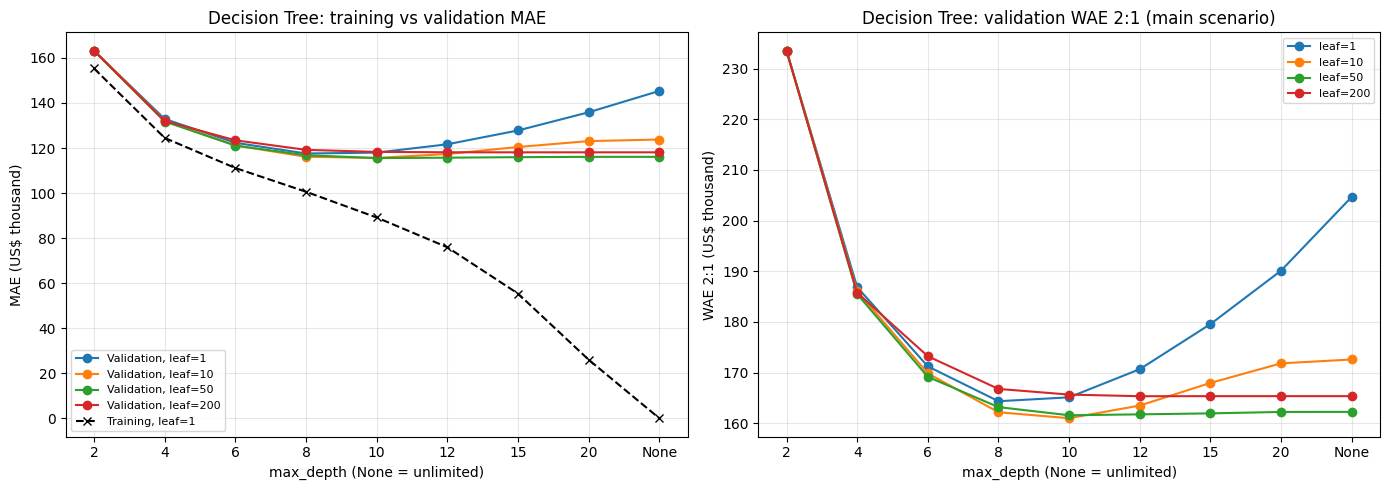

In [6]:
depth_labels = [str(depth) for depth in DT_GRID["max_depth"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for leaf in DT_GRID["min_samples_leaf"]:
    subset = dt_results.loc[dt_results["min_samples_leaf"] == leaf].set_index("max_depth").loc[depth_labels]
    axes[0].plot(depth_labels, subset["MAE"] / 1e3, marker="o", label=f"Validation, leaf={leaf}")
    axes[1].plot(depth_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"leaf={leaf}")
leaf1 = dt_results.loc[dt_results["min_samples_leaf"] == 1].set_index("max_depth").loc[depth_labels]
axes[0].plot(depth_labels, leaf1["train_MAE"] / 1e3, color="black", linestyle="--", marker="x", label="Training, leaf=1")
axes[0].set_title("Decision Tree: training vs validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Decision Tree: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("max_depth (None = unlimited)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T1_decision_tree_complexity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Random Forest

### 5a. Number of trees

The number of trees is not a complexity parameter in the usual sense: more trees reduce variance without increasing overfitting, but cost time. The forest is grown with `warm_start` and the smallest size whose validation MAE is within 0.5% of the best value on the path is used for the grid. Out-of-bag (OOB) error is shown alongside validation error; OOB error is a within-period estimate, so the gap between them indicates how much accuracy is lost when predicting a later period.

 n_estimators  validation_MAE  validation_WAE_2_1  OOB_MAE  incremental_fit_seconds
           25       102,873.9           142,286.6 99,346.3                      1.8
           50       101,750.3           140,708.8 96,406.6                      2.3
          100       101,374.9           140,037.3 95,148.2                      3.9
          200       101,033.0           139,497.4 94,456.4                      7.9
          300       100,971.6           139,412.4 94,257.0                      9.0

Selected n_estimators for the grid: 100


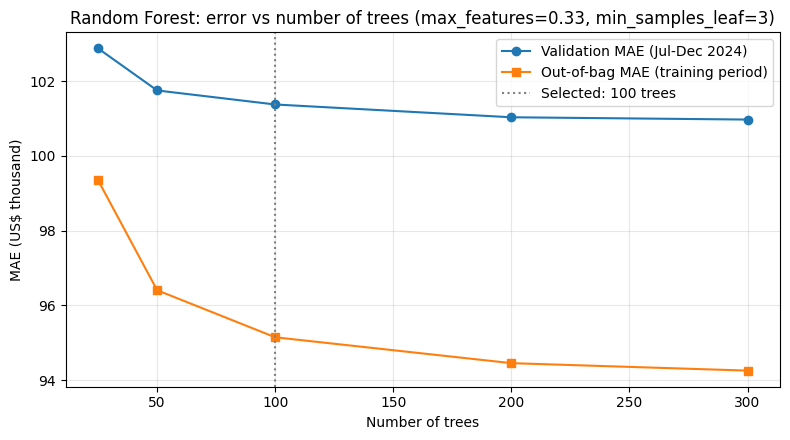

In [7]:
import warnings

path_rows = []
forest_path = RandomForestRegressor(
    n_estimators=RF_N_ESTIMATORS_PATH[0],
    warm_start=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    **RF_PATH_CONFIG,
)
for n_trees in RF_N_ESTIMATORS_PATH:
    forest_path.set_params(n_estimators=n_trees)
    start = time.perf_counter()
    with warnings.catch_warnings():
        # With 25 trees a handful of rows are never out of bag; they are excluded below.
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        forest_path.fit(X_train, y_train_fit)
    elapsed = time.perf_counter() - start
    oob_pred = to_dollars(forest_path.oob_prediction_)
    has_oob = forest_path.oob_prediction_ != 0          # rows never left out of bag are returned as 0
    val_pred = to_dollars(forest_path.predict(X_val))
    path_rows.append({
        "n_estimators": n_trees,
        "validation_MAE": mean_absolute_error(y_val, val_pred),
        "validation_WAE_2_1": weighted_absolute_error(y_val, val_pred, 2, 1),
        "OOB_MAE": mean_absolute_error(y_train[has_oob], oob_pred[has_oob]),
        "incremental_fit_seconds": elapsed,
    })
del forest_path
gc.collect()

rf_path = pd.DataFrame(path_rows)
best_path_mae = rf_path["validation_MAE"].min()
RF_N_ESTIMATORS = int(rf_path.loc[rf_path["validation_MAE"] <= 1.005 * best_path_mae, "n_estimators"].min())
rf_path.to_csv(OUT_DIR / "rf_n_estimators_path.csv", index=False)
print(rf_path.to_string(index=False, float_format=lambda v: f"{v:,.1f}"))
print(f"\nSelected n_estimators for the grid: {RF_N_ESTIMATORS}")

fig, axis = plt.subplots(figsize=(8, 4.5))
axis.plot(rf_path["n_estimators"], rf_path["validation_MAE"] / 1e3, marker="o", label="Validation MAE (Jul-Dec 2024)")
axis.plot(rf_path["n_estimators"], rf_path["OOB_MAE"] / 1e3, marker="s", label="Out-of-bag MAE (training period)")
axis.axvline(RF_N_ESTIMATORS, color="grey", linestyle=":", label=f"Selected: {RF_N_ESTIMATORS} trees")
axis.set_xlabel("Number of trees")
axis.set_ylabel("MAE (US$ thousand)")
axis.set_title(f"Random Forest: error vs number of trees ({configuration_text(RF_PATH_CONFIG)})")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "T2_rf_n_estimators.png", dpi=150, bbox_inches="tight")
plt.show()

### 5b. Complexity grid

`min_samples_leaf` limits how finely each tree fits the training data (larger = simpler trees). `max_features` sets the share of predictors considered at each split; smaller values decorrelate the trees and add randomness. Each configuration is fitted once and scored under all three WAE scenarios with fixed predictions.

In [8]:
grid_start = time.perf_counter()
run_number = 0
for max_features in RF_GRID["max_features"]:
    for leaf in RF_GRID["min_samples_leaf"]:
        run_number += 1
        params = {"n_estimators": RF_N_ESTIMATORS, "max_features": max_features, "min_samples_leaf": leaf}
        start = time.perf_counter()
        forest = RandomForestRegressor(oob_score=True, random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
        forest.fit(X_train, y_train_fit)
        fit_seconds = time.perf_counter() - start
        has_oob = forest.oob_prediction_ != 0
        oob_mae = mean_absolute_error(y_train[has_oob], to_dollars(forest.oob_prediction_)[has_oob])
        row = record_run(f"R{run_number:03d}", "Random Forest", params, forest, fit_seconds, oob_mae)
        print(f"{row['run_id']} {row['configuration']}: val MAE {row['MAE']:,.0f}, "
              f"WAE 2:1 {row['WAE_2_1']:,.0f}, OOB MAE {oob_mae:,.0f} ({fit_seconds:.0f}s)")
        del forest
        gc.collect()

rf_results = pd.DataFrame([row for row in run_rows if row["model_family"] == "Random Forest"])
print(f"\nRandom Forest grid finished in {(time.perf_counter() - grid_start) / 60:.1f} minutes.")

R001 n_estimators=100, max_features=0.2, min_samples_leaf=1: val MAE 102,524, WAE 2:1 142,358, OOB MAE 96,130 (6s)
R002 n_estimators=100, max_features=0.2, min_samples_leaf=3: val MAE 101,091, WAE 2:1 139,391, OOB MAE 95,049 (5s)
R003 n_estimators=100, max_features=0.2, min_samples_leaf=10: val MAE 101,231, WAE 2:1 139,890, OOB MAE 94,789 (4s)
R004 n_estimators=100, max_features=0.2, min_samples_leaf=30: val MAE 103,695, WAE 2:1 143,375, OOB MAE 97,011 (3s)
R005 n_estimators=100, max_features=0.33, min_samples_leaf=1: val MAE 102,546, WAE 2:1 142,600, OOB MAE 96,367 (8s)
R006 n_estimators=100, max_features=0.33, min_samples_leaf=3: val MAE 101,375, WAE 2:1 140,037, OOB MAE 95,148 (6s)
R007 n_estimators=100, max_features=0.33, min_samples_leaf=10: val MAE 101,173, WAE 2:1 139,638, OOB MAE 94,441 (5s)
R008 n_estimators=100, max_features=0.33, min_samples_leaf=30: val MAE 103,209, WAE 2:1 142,698, OOB MAE 96,506 (4s)
R009 n_estimators=100, max_features=0.5, min_samples_leaf=1: val MAE 102

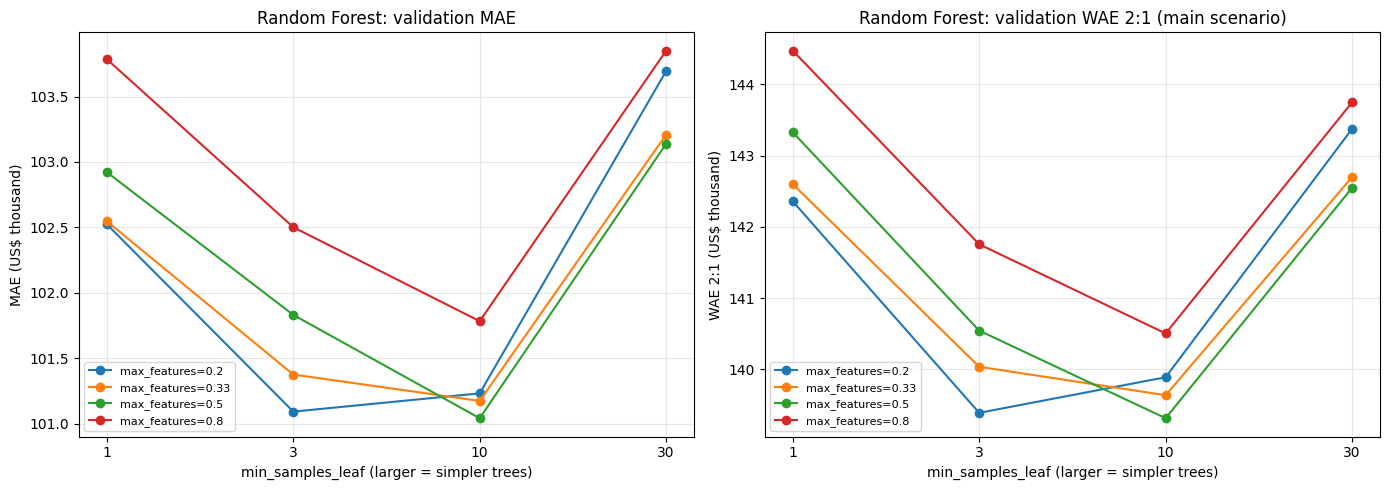

Training, out-of-bag and validation MAE (US$):
run_id                                            configuration  train_MAE  OOB_MAE  validation_MAE  validation_minus_OOB
  R001   n_estimators=100, max_features=0.2, min_samples_leaf=1     35,421   96,130         102,524                 6,393
  R002   n_estimators=100, max_features=0.2, min_samples_leaf=3     51,647   95,049         101,091                 6,042
  R003  n_estimators=100, max_features=0.2, min_samples_leaf=10     75,235   94,789         101,231                 6,441
  R004  n_estimators=100, max_features=0.2, min_samples_leaf=30     88,948   97,011         103,695                 6,684
  R005  n_estimators=100, max_features=0.33, min_samples_leaf=1     35,504   96,367         102,546                 6,180
  R006  n_estimators=100, max_features=0.33, min_samples_leaf=3     49,507   95,148         101,375                 6,227
  R007 n_estimators=100, max_features=0.33, min_samples_leaf=10     73,297   94,441         101,173

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for max_features in RF_GRID["max_features"]:
    subset = rf_results.loc[rf_results["max_features"] == max_features].sort_values("min_samples_leaf")
    leaf_labels = subset["min_samples_leaf"].astype(int).astype(str)
    axes[0].plot(leaf_labels, subset["MAE"] / 1e3, marker="o", label=f"max_features={max_features}")
    axes[1].plot(leaf_labels, subset["WAE_2_1"] / 1e3, marker="o", label=f"max_features={max_features}")
axes[0].set_title("Random Forest: validation MAE")
axes[0].set_ylabel("MAE (US$ thousand)")
axes[1].set_title("Random Forest: validation WAE 2:1 (main scenario)")
axes[1].set_ylabel("WAE 2:1 (US$ thousand)")
for axis in axes:
    axis.set_xlabel("min_samples_leaf (larger = simpler trees)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T3_rf_complexity_grid.png", dpi=150, bbox_inches="tight")
plt.show()

gap_table = rf_results[["run_id", "configuration", "train_MAE", "OOB_MAE", "MAE"]].rename(
    columns={"MAE": "validation_MAE"}
)
gap_table["validation_minus_OOB"] = gap_table["validation_MAE"] - gap_table["OOB_MAE"]
print("Training, out-of-bag and validation MAE (US$):")
print(gap_table.to_string(index=False, float_format=lambda v: f"{v:,.0f}"))

## 6. Scenario-specific selection and the unified results table

Following the group convention, each model family is selected separately under each WAE scenario. The winner table uses the same columns and scenario labels as `data/result/linear_models/scenario_validation_winners.csv`. The pre-specified main scenario is WAE 2:1; the other two are sensitivity results. A supplementary table also lists each family's lowest-MSE configuration (the within-family rule used in the Boosting notebook), so the tree results can be merged under either selection rule.

In [10]:
all_runs = pd.DataFrame(run_rows)
all_runs.to_csv(OUT_DIR / "tree_validation_results_all_runs.csv", index=False)

winner_rows = []
for family in ["Decision Tree", "Random Forest"]:
    family_runs = all_runs.loc[all_runs["model_family"] == family]
    for metric, (scenario_name, _, _) in SCENARIOS.items():
        best = family_runs.loc[family_runs[metric].idxmin()]
        winner_rows.append({
            "model_family": family,
            "scenario": scenario_name,
            "winning_configuration": best["configuration"],
            "feature_set": best["feature_set"],
            "selected_WAE": best[metric],
            "MSE": best["MSE"],
            "R2": best["R2"],
            "MAE": best["MAE"],
            "run_id": best["run_id"],
        })
scenario_winners = pd.DataFrame(winner_rows)
scenario_winners.drop(columns="run_id").to_csv(OUT_DIR / "tree_scenario_validation_winners.csv", index=False)
print(scenario_winners.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

# Supplementary: lowest validation MSE per family, scored under all three WAE scenarios with fixed predictions.
mse_champions = (
    all_runs.sort_values(["MSE", "run_id"])
    .drop_duplicates("model_family")
    [["model_family", "run_id", "configuration", "feature_set", "MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]]
    .reset_index(drop=True)
)
mse_champions.to_csv(OUT_DIR / "tree_mse_champions.csv", index=False)
print("\nSupplementary: lowest-MSE configuration per family")
print(mse_champions.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

 model_family                                    scenario                                   winning_configuration                         feature_set  selected_WAE                 MSE     R2          MAE run_id
Decision Tree         Main - Overvaluation Priority (2:1)                       max_depth=10, min_samples_leaf=10 Official split CSV (209 predictors)  160,998.1234 59,195,005,840.2818 0.6896 115,601.4060   T018
Decision Tree          Alternative - Equal Priority (1:1)                       max_depth=10, min_samples_leaf=50 Official split CSV (209 predictors)  115,538.3875 61,896,057,811.3162 0.6755 115,538.3875   T019
Decision Tree Alternative - Undervaluation Priority (1:2)                       max_depth=10, min_samples_leaf=50 Official split CSV (209 predictors)  185,036.4453 61,896,057,811.3162 0.6755 115,538.3875   T019
Random Forest         Main - Overvaluation Priority (2:1) n_estimators=100, max_features=0.5, min_samples_leaf=10 Official split CSV (209 predictors)  139,3

### 6a. Fixed-prediction comparison under all three scenarios

For the configuration selected under the main 2:1 scenario, predictions are held fixed and scored under all three weightings against the Global Mean baseline (the format required for 4c).

In [11]:
main_winners = scenario_winners.loc[scenario_winners["scenario"] == SCENARIOS[MAIN_METRIC][0]]
fixed_rows = []
for _, winner in main_winners.iterrows():
    model_pred = validation_predictions[winner["run_id"]]
    for metric, (scenario_name, over_w, under_w) in SCENARIOS.items():
        model_wae = weighted_absolute_error(y_val, model_pred, over_w, under_w)
        baseline_wae = weighted_absolute_error(y_val, baseline_prediction, over_w, under_w)
        fixed_rows.append({
            "scenario": scenario_name,
            "model_family": winner["model_family"],
            "feature_set": winner["feature_set"],
            "configuration": winner["winning_configuration"],
            "model_WAE": model_wae,
            "baseline_WAE": baseline_wae,
            "reduction_percent": 100 * (1 - model_wae / baseline_wae),
        })
fixed_comparison = pd.DataFrame(fixed_rows)
fixed_comparison.to_csv(OUT_DIR / "tree_selected_model_fixed_scenario_comparison.csv", index=False)
print(fixed_comparison.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

# Validation predictions of every scenario winner, keyed by transaction for later merging.
prediction_export = val_ids[["transaction_id", "property_id", "sale_date"]].copy()
prediction_export["actual_sale_price"] = y_val
for run_id in pd.unique(pd.concat([scenario_winners["run_id"], mse_champions["run_id"]])):
    prediction_export[f"pred_{run_id}"] = validation_predictions[run_id]
prediction_export.to_csv(OUT_DIR / "tree_validation_predictions.csv", index=False)
print("\nSaved scenario winners, fixed-scenario comparison and validation predictions to", OUT_DIR)

                                   scenario  model_family                         feature_set                                           configuration  model_WAE  baseline_WAE  reduction_percent
        Main - Overvaluation Priority (2:1) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 160,998.12    342,381.82              52.98
         Alternative - Equal Priority (1:1) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 115,601.41    238,599.62              51.55
Alternative - Undervaluation Priority (1:2) Decision Tree Official split CSV (209 predictors)                       max_depth=10, min_samples_leaf=10 185,806.09    373,417.03              50.24
        Main - Overvaluation Priority (2:1) Random Forest Official split CSV (209 predictors) n_estimators=100, max_features=0.5, min_samples_leaf=10 139,315.50    342,381.82              59.31
         Alternative - Equal P

### 6b. Prediction bias of every configuration

For every tree configuration, the systematic direction of the validation errors is summarised: mean signed error (predicted − actual), median estimate/price ratio and the share of sales overvalued, alongside RMSE, overall and by month. These columns are also used by the time-variable comparison in 6c.

In [12]:
VARIANT_LABEL = "B_month_index" if ADD_TIME_TREND else "A_no_time"
N_PREDICTORS = X_train.shape[1]
validation_month = val_ids["sale_date"].dt.strftime("%Y-%m").to_numpy()

bias_rows = []
monthly_bias_rows = []
for run_id, prediction in validation_predictions.items():
    error = prediction - y_val
    bias_rows.append({
        "run_id": run_id,
        "variant": VARIANT_LABEL,
        "n_predictors": N_PREDICTORS,
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / y_val)),
        "share_overvalued": float((error > 0).mean()),
    })
    for month in np.unique(validation_month):
        in_month = validation_month == month
        monthly_bias_rows.append({
            "run_id": run_id,
            "variant": VARIANT_LABEL,
            "sale_month": month,
            "sales": int(in_month.sum()),
            "mean_signed_error": float(error[in_month].mean()),
            "median_ratio": float(np.median(prediction[in_month] / y_val[in_month])),
            "MAE": float(np.abs(error[in_month]).mean()),
        })
bias_table = all_runs[["run_id", "model_family", "configuration", "MSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2"]].merge(
    pd.DataFrame(bias_rows), on="run_id", how="left", validate="one_to_one"
)
bias_table.to_csv(OUT_DIR / "tree_validation_bias_all_runs.csv", index=False)
monthly_bias = pd.DataFrame(monthly_bias_rows)
monthly_bias.to_csv(OUT_DIR / "tree_validation_bias_by_month_all_runs.csv", index=False)
print(f"Variant: {VARIANT_LABEL} ({N_PREDICTORS} predictors)")
print("Bias summary of the scenario winners:")
print(bias_table.loc[bias_table["run_id"].isin(scenario_winners["run_id"])]
      .to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

Variant: A_no_time (209 predictors)
Bias summary of the scenario winners:
run_id  model_family                                           configuration                MSE    R2         MAE     WAE_2_1     WAE_1_1     WAE_1_2   variant  n_predictors        RMSE  mean_signed_error  median_ratio  share_overvalued
  T018 Decision Tree                       max_depth=10, min_samples_leaf=10 59,195,005,840.282 0.690 115,601.406 160,998.123 115,601.406 185,806.095 A_no_time           209 243,300.238        -24,807.971         0.946             0.422
  T019 Decision Tree                       max_depth=10, min_samples_leaf=50 61,896,057,811.316 0.675 115,538.388 161,578.717 115,538.388 185,036.445 A_no_time           209 248,789.183        -23,457.728         0.948             0.426
  R003 Random Forest n_estimators=100, max_features=0.2, min_samples_leaf=10 49,191,916,835.870 0.742 101,230.951 139,890.420 101,230.951 163,802.432 A_no_time           209 221,792.509        -23,912.012         0.

### 6c. Time-variable comparison for the tree models (Model A vs Model B)

Group plan: does adding one time variable, `months_since_2023_01` = (year − 2023) × 12 + (month − 1) taken from the membership sale dates, reduce the systematic underestimation, and does it change the selection under WAE 2:1?

- **Model A**: the 209 shared predictors (the results above).
- **Model B**: Model A plus `months_since_2023_01` (210 predictors). Everything else is identical: dollar target, seed, the same Decision Tree and Random Forest grids with the same `run_id`s, and the forest size selected in 5a.
- **Fixed hyperparameters**: Model A's selected configuration refitted with the time variable (the same `run_id` in Model B).
- **Retuned**: the configuration Model B selects from the same grid under the same rule.

Selection uses the main rule (lowest WAE 2:1) and, as a supplement, the lowest MSE. The pre-specified decision rule is applied to the change in WAE 2:1: a reduction of more than 1% adopts the time variable; MAE better but WAE 2:1 worse keeps A and the trade-off is reported; a change within 1% keeps A. Training months run from 0 to 17 and validation months from 18 to 23, so trees cannot extrapolate the trend: they can only treat the validation period like the latest training months.

Model B grid (52 configurations) finished in 3.1 minutes.
Time-variable comparison (validation, Jul-Dec 2024):
 model_family                    selected_by            comparison       variant                                           configuration         MAE     WAE_2_1  mean_signed_error  median_ratio  share_overvalued  WAE_2_1_change_pct_vs_A                                                    rule_outcome
Decision Tree      main rule: lowest WAE 2:1 fixed_hyperparameters     A_no_time                       max_depth=10, min_samples_leaf=10 115,601.406 160,998.123        -24,807.971         0.946             0.422                      NaN                                                                
Decision Tree      main rule: lowest WAE 2:1 fixed_hyperparameters B_month_index                       max_depth=10, min_samples_leaf=10 116,182.170 164,623.295        -19,299.920         0.961             0.444                    2.252                         Keep A: WAE 2:1 worsens by

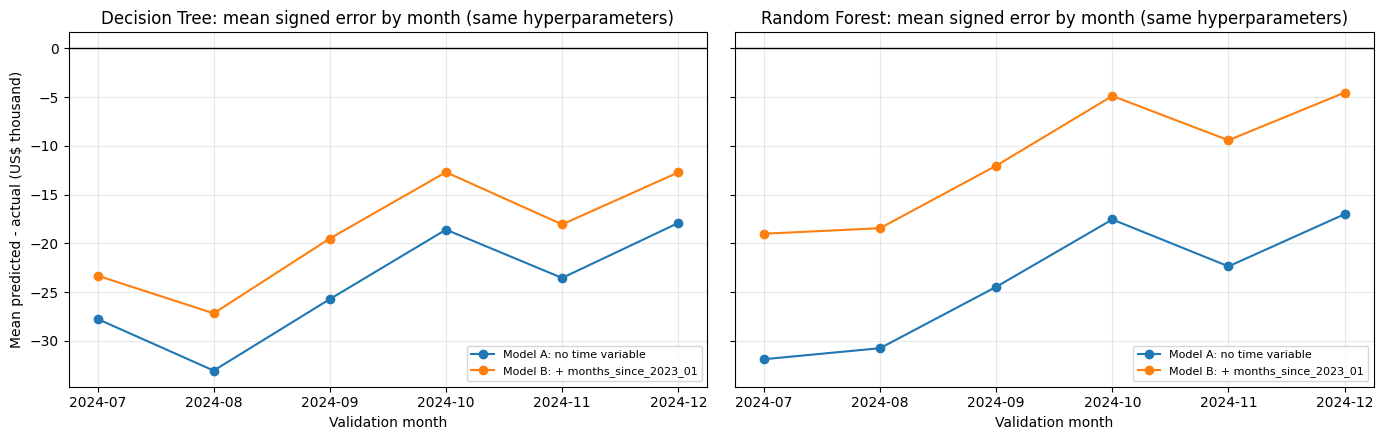

In [13]:
TIME_TREND_DIR = OUT_DIR / "time_trend"
TIME_TREND_DIR.mkdir(parents=True, exist_ok=True)
REQUIRED_COLUMNS = [
    "model_family", "variant", "comparison", "configuration", "n_predictors",
    "MSE", "RMSE", "R2", "MAE", "WAE_2_1", "WAE_1_1", "WAE_1_2",
    "mean_signed_error", "median_ratio", "share_overvalued",
]
SELECTION_RULES = {"WAE_2_1": "main rule: lowest WAE 2:1", "MSE": "supplementary rule: lowest MSE"}
assert not ADD_TIME_TREND, "Section 6c treats the main analysis as Model A, so ADD_TIME_TREND must stay False."


def months_since_2023_01(members):
    dates = members["sale_date"]
    return ((dates.dt.year - 2023) * 12 + dates.dt.month - 1).to_numpy()


X_train_B = X_train.assign(months_since_2023_01=months_since_2023_01(train_ids))
X_val_B = X_val.assign(months_since_2023_01=months_since_2023_01(val_ids))
assert X_train_B.shape[1] == X_train.shape[1] + 1 == N_PREDICTORS + 1
assert X_train_B["months_since_2023_01"].between(0, 17).all() and X_val_B["months_since_2023_01"].between(18, 23).all()


def score_variant(run_id, family, configuration, prediction, variant, n_predictors):
    error = prediction - y_val
    return {
        "run_id": run_id, "model_family": family, "configuration": configuration,
        "variant": variant, "n_predictors": n_predictors,
        **evaluate_regression_predictions(y_val, prediction),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "mean_signed_error": float(error.mean()),
        "median_ratio": float(np.median(prediction / y_val)),
        "share_overvalued": float((error > 0).mean()),
    }


# Model B: the same grids and run_ids as sections 4 and 5b, with the time variable added.
b_rows, b_predictions = [], {}
start = time.perf_counter()
run_number = 0
for depth in DT_GRID["max_depth"]:
    for leaf in DT_GRID["min_samples_leaf"]:
        run_number += 1
        run_id = f"T{run_number:03d}"
        params = {"max_depth": depth, "min_samples_leaf": leaf}
        tree = DecisionTreeRegressor(random_state=RANDOM_STATE, **params).fit(X_train_B, y_train_fit)
        b_predictions[run_id] = to_dollars(tree.predict(X_val_B))
        b_rows.append(score_variant(run_id, "Decision Tree", configuration_text(params), b_predictions[run_id],
                                    "B_month_index", X_train_B.shape[1]))
        del tree
run_number = 0
for max_features in RF_GRID["max_features"]:
    for leaf in RF_GRID["min_samples_leaf"]:
        run_number += 1
        run_id = f"R{run_number:03d}"
        params = {"n_estimators": RF_N_ESTIMATORS, "max_features": max_features, "min_samples_leaf": leaf}
        forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **params).fit(X_train_B, y_train_fit)
        b_predictions[run_id] = to_dollars(forest.predict(X_val_B))
        b_rows.append(score_variant(run_id, "Random Forest", configuration_text(params), b_predictions[run_id],
                                    "B_month_index", X_train_B.shape[1]))
        del forest
        gc.collect()
b_runs = pd.DataFrame(b_rows)
a_runs = bias_table.copy()
b_runs.to_csv(TIME_TREND_DIR / "model_B_validation_results_all_runs.csv", index=False)
print(f"Model B grid ({len(b_runs)} configurations) finished in {(time.perf_counter() - start) / 60:.1f} minutes.")

# The same run_id must mean the same hyperparameters in A and B.
check = a_runs[["run_id", "configuration"]].merge(b_runs[["run_id", "configuration"]], on="run_id",
                                                  suffixes=("_A", "_B"), validate="one_to_one")
assert len(check) == len(a_runs) == len(b_runs)
assert (check["configuration_A"] == check["configuration_B"]).all()


def rule_outcome(wae_change_pct, mae_change_pct):
    if wae_change_pct < -1:
        return "Adopt time variable: WAE 2:1 falls by more than 1%"
    if wae_change_pct > 0 and mae_change_pct < 0:
        return "Keep A: MAE improves but WAE 2:1 worsens (report the trade-off)"
    if abs(wae_change_pct) <= 1:
        return "Keep A: change within 1%"
    return "Keep A: WAE 2:1 worsens by more than 1%"


def select(runs, family, metric):
    family_runs = runs.loc[runs["model_family"] == family]
    return family_runs.loc[family_runs[metric].idxmin()]


comparison_rows, monthly_rows = [], []
validation_month = val_ids["sale_date"].dt.strftime("%Y-%m").to_numpy()
for family in ["Decision Tree", "Random Forest"]:
    for metric, rule in SELECTION_RULES.items():
        a_choice = select(a_runs, family, metric)
        b_fixed = b_runs.loc[b_runs["run_id"] == a_choice["run_id"]].iloc[0]
        b_retuned = select(b_runs, family, metric)
        for comparison, b_row in [("fixed_hyperparameters", b_fixed), ("retuned", b_retuned)]:
            wae_change = 100 * (b_row["WAE_2_1"] / a_choice["WAE_2_1"] - 1)
            mae_change = 100 * (b_row["MAE"] / a_choice["MAE"] - 1)
            for row, is_b in [(a_choice, False), (b_row, True)]:
                record = {column: row[column] for column in REQUIRED_COLUMNS if column != "comparison"}
                record.update({
                    "comparison": comparison, "run_id": row["run_id"], "selected_by": rule,
                    "WAE_2_1_change_pct_vs_A": wae_change if is_b else np.nan,
                    "MAE_change_pct_vs_A": mae_change if is_b else np.nan,
                    "rule_outcome": rule_outcome(wae_change, mae_change) if is_b else "",
                })
                comparison_rows.append(record)
                prediction = b_predictions[row["run_id"]] if is_b else validation_predictions[row["run_id"]]
                error = prediction - y_val
                for month in np.unique(validation_month):
                    in_month = validation_month == month
                    monthly_rows.append({
                        "model_family": family, "selected_by": rule, "comparison": comparison,
                        "variant": row["variant"], "configuration": row["configuration"], "sale_month": month,
                        "sales": int(in_month.sum()), "mean_signed_error": float(error[in_month].mean()),
                        "median_ratio": float(np.median(prediction[in_month] / y_val[in_month])),
                        "MAE": float(np.abs(error[in_month]).mean()),
                    })

extra_columns = ["run_id", "selected_by", "WAE_2_1_change_pct_vs_A", "MAE_change_pct_vs_A", "rule_outcome"]
time_trend_table = pd.DataFrame(comparison_rows)[REQUIRED_COLUMNS + extra_columns]
time_trend_monthly = pd.DataFrame(monthly_rows)
time_trend_table.to_csv(TIME_TREND_DIR / "tree_time_trend_comparison.csv", index=False)
time_trend_monthly.to_csv(TIME_TREND_DIR / "tree_time_trend_monthly_bias.csv", index=False)
shared_inputs = DATA_DIR / "result" / "time_trend_comparison" / "inputs"
shared_inputs.mkdir(parents=True, exist_ok=True)
time_trend_table.to_csv(shared_inputs / "M3_trees_time_trend.csv", index=False)   # copy for the group summary

show = ["model_family", "selected_by", "comparison", "variant", "configuration", "MAE", "WAE_2_1",
        "mean_signed_error", "median_ratio", "share_overvalued", "WAE_2_1_change_pct_vs_A", "rule_outcome"]
print("Time-variable comparison (validation, Jul-Dec 2024):")
print(time_trend_table[show].to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
main_monthly = time_trend_monthly.loc[time_trend_monthly["selected_by"] == SELECTION_RULES["WAE_2_1"]]
print("\nMonthly mean signed error (predicted - actual), main-rule configurations:")
print(main_monthly.drop_duplicates(["model_family", "comparison", "variant", "sale_month"])
      .pivot_table(index=["model_family", "comparison", "variant"], columns="sale_month", values="mean_signed_error")
      .to_string(float_format=lambda v: f"{v:,.0f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for axis, family in zip(axes, ["Decision Tree", "Random Forest"]):
    subset = main_monthly.loc[(main_monthly["model_family"] == family)
                              & (main_monthly["comparison"] == "fixed_hyperparameters")]
    for variant, label in [("A_no_time", "Model A: no time variable"), ("B_month_index", "Model B: + months_since_2023_01")]:
        line = subset.loc[subset["variant"] == variant].sort_values("sale_month")
        axis.plot(line["sale_month"], line["mean_signed_error"] / 1e3, marker="o", label=label)
    axis.axhline(0, color="black", linewidth=1)
    axis.set_title(f"{family}: mean signed error by month (same hyperparameters)")
    axis.set_xlabel("Validation month")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
axes[0].set_ylabel("Mean predicted - actual (US$ thousand)")
plt.tight_layout()
fig.savefig(FIG_DIR / "T7_time_variable_monthly_bias.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Validation diagnostics for the main-scenario Random Forest

The selected forest is refitted once (same seed, identical predictions) to inspect feature importance and the structure of its errors. These diagnostics use validation data only and prepare the arguments for 4a and 4b; the final numbers in 4a come from the frozen final model on the 2025 test set (section 13).

Selected Random Forest (WAE 2:1): n_estimators=100, max_features=0.5, min_samples_leaf=10
                                            impurity_importance  permutation_MAE_increase  permutation_std
char_bldg_sf                                             0.1496               37,636.7825         574.6364
meta_nbhd_code_te                                        0.0744               15,541.4808         376.9514
loc_school_secondary_district_geoid_te                   0.1664                6,205.9763         221.2095
inter_log1p_land_bldg_product                            0.0280                5,416.0000         166.7294
loc_property_zip_te                                      0.1450                4,531.6151         125.3568
loc_census_tract_geoid_te                                0.0311                2,795.0047         191.1424
char_yrblt                                               0.0125                2,421.2634         124.8282
char_fbath                                            

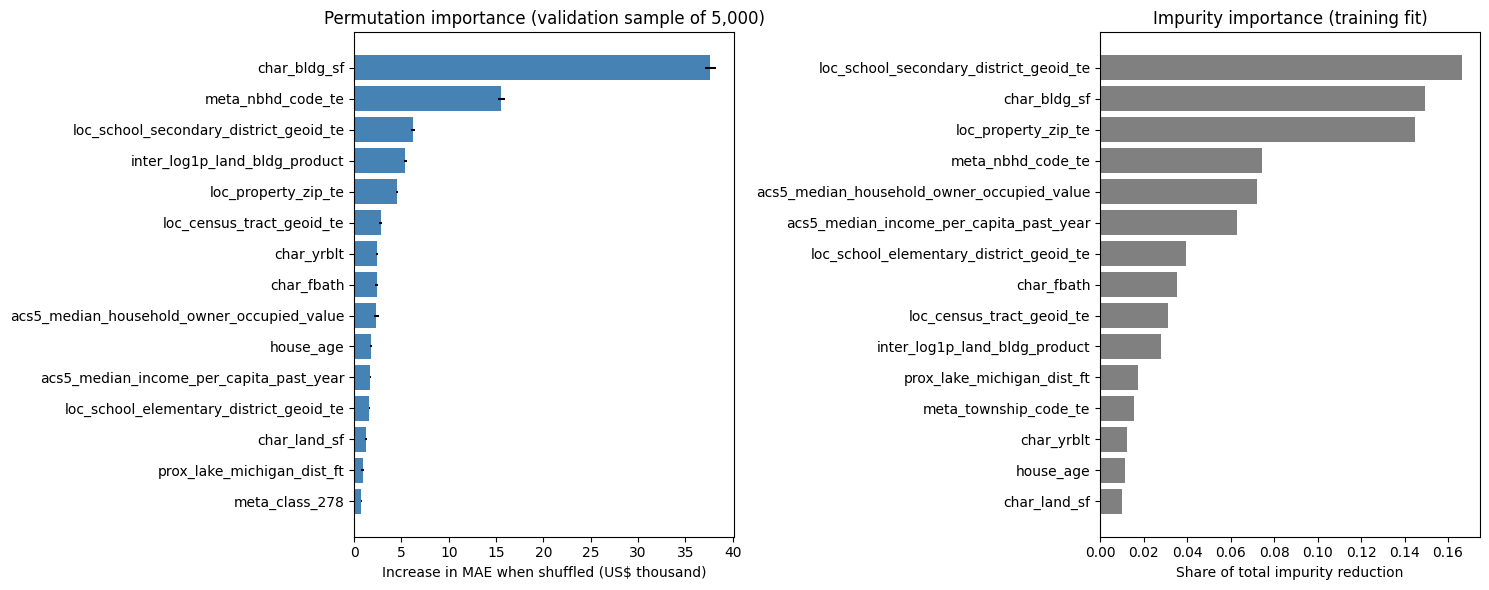

In [14]:
selected_rf = main_winners.loc[main_winners["model_family"] == "Random Forest"].iloc[0]
selected_row = all_runs.loc[all_runs["run_id"] == selected_rf["run_id"]].iloc[0]
SELECTED_RF_PARAMS = {
    "n_estimators": int(selected_row["n_estimators"]),
    "max_features": float(selected_row["max_features"]),
    "min_samples_leaf": int(selected_row["min_samples_leaf"]),
}
print(f"Selected Random Forest (WAE 2:1): {configuration_text(SELECTED_RF_PARAMS)}")

selected_forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **SELECTED_RF_PARAMS)
selected_forest.fit(X_train, y_train_fit)
rf_val_pred = to_dollars(selected_forest.predict(X_val))
assert np.allclose(rf_val_pred, validation_predictions[selected_rf["run_id"]])

impurity = pd.Series(selected_forest.feature_importances_, index=X_train.columns, name="impurity_importance")


def dollar_mae_scorer(estimator, features, target_fit_scale):
    return -mean_absolute_error(to_dollars(target_fit_scale), to_dollars(estimator.predict(features)))


sample_index = val_raw.sample(n=min(PERMUTATION_SAMPLE, len(val_raw)), random_state=RANDOM_STATE).index
permutation = permutation_importance(
    selected_forest,
    X_val.loc[sample_index],
    to_fit_scale(y_val[sample_index]),
    scoring=dollar_mae_scorer,
    n_repeats=PERMUTATION_REPEATS,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame({
    "impurity_importance": impurity,
    "permutation_MAE_increase": permutation.importances_mean,
    "permutation_std": permutation.importances_std,
}).sort_values("permutation_MAE_increase", ascending=False)
importance.to_csv(OUT_DIR / "rf_feature_importance.csv", index_label="feature")
print(importance.head(15).to_string(float_format=lambda v: f"{v:,.4f}"))

top = importance.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(top.index, top["permutation_MAE_increase"] / 1e3, xerr=top["permutation_std"] / 1e3, color="steelblue")
axes[0].set_title(f"Permutation importance (validation sample of {len(sample_index):,})")
axes[0].set_xlabel("Increase in MAE when shuffled (US$ thousand)")
top_impurity = impurity.sort_values().tail(15)
axes[1].barh(top_impurity.index, top_impurity.values, color="grey")
axes[1].set_title("Impurity importance (training fit)")
axes[1].set_xlabel("Share of total impurity reduction")
plt.tight_layout()
fig.savefig(FIG_DIR / "T4_rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
township_lookup = pd.read_csv(
    DATA_DIR / "properties_2022.csv",
    usecols=["property_id", "meta_township_code"],
    dtype={"property_id": str, "meta_township_code": str},
)
diagnostics = val_ids.merge(township_lookup, on="property_id", how="left", validate="many_to_one")
assert len(diagnostics) == len(val_ids) and diagnostics["meta_township_code"].notna().all()
diagnostics["actual"] = y_val
diagnostics["predicted"] = rf_val_pred
diagnostics["error"] = diagnostics["predicted"] - diagnostics["actual"]
diagnostics["ratio"] = diagnostics["predicted"] / diagnostics["actual"]
diagnostics["abs_pct_error"] = diagnostics["error"].abs() / diagnostics["actual"]
diagnostics["seen_in_training"] = diagnostics["property_id"].isin(set(train_ids["property_id"]))
diagnostics["price_decile"] = pd.qcut(diagnostics["actual"], 10, labels=[f"D{i}" for i in range(1, 11)])
diagnostics["sale_month"] = diagnostics["sale_date"].dt.strftime("%Y-%m")


def group_summary(frame, by):
    grouped = frame.groupby(by, observed=True)
    return pd.DataFrame({
        "sales": grouped.size(),
        "median_price": grouped["actual"].median(),
        "MAE": grouped["error"].apply(lambda e: e.abs().mean()),
        "median_APE": grouped["abs_pct_error"].median(),
        "mean_signed_error": grouped["error"].mean(),
        "median_ratio": grouped["ratio"].median(),
        "share_overvalued": grouped["error"].apply(lambda e: (e > 0).mean()),
    })


overall_ratio = pd.DataFrame({
    "Random Forest": assessment_ratio_statistics(y_val, rf_val_pred),
    "Global Mean": assessment_ratio_statistics(y_val, baseline_prediction),
}).T
print("Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):")
print(overall_ratio.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile = group_summary(diagnostics, "price_decile")
by_month = group_summary(diagnostics, "sale_month")
by_seen = group_summary(diagnostics, "seen_in_training")
by_township = group_summary(diagnostics, "meta_township_code").sort_values("sales", ascending=False)
for name, table in [("price decile", by_decile), ("sale month", by_month),
                    ("property seen in training", by_seen), ("township (10 largest)", by_township.head(10))]:
    print(f"\nErrors by {name}:")
    print(table.to_string(float_format=lambda v: f"{v:,.3f}"))

by_decile.to_csv(OUT_DIR / "rf_validation_errors_by_price_decile.csv")
by_month.to_csv(OUT_DIR / "rf_validation_errors_by_month.csv")
by_seen.to_csv(OUT_DIR / "rf_validation_errors_by_seen_status.csv")
by_township.to_csv(OUT_DIR / "rf_validation_errors_by_township.csv")
overall_ratio.to_csv(OUT_DIR / "rf_validation_ratio_statistics.csv")

Assessment-ratio statistics (ratio = estimate / sale price; IAAO guide for single-family: COD 5-15, PRD 0.98-1.03):
               median_ratio    COD   PRD
Random Forest         0.950 33.056 1.162
Global Mean           1.199 73.971 1.793

Errors by price decile:
              sales  median_price         MAE  median_APE  mean_signed_error  median_ratio  share_overvalued
price_decile                                                                                                
D1             1822    94,440.000  77,476.947       0.765         75,294.197         1.765             0.935
D2             1807   175,000.000  58,260.353       0.251         28,815.160         1.088             0.583
D3             1824   240,000.000  59,298.780       0.199            527.678         0.961             0.446
D4             1888   285,000.000  59,802.870       0.154         -9,567.402         0.934             0.363
D5             1743   325,000.000  61,610.583       0.143        -19,142.475      

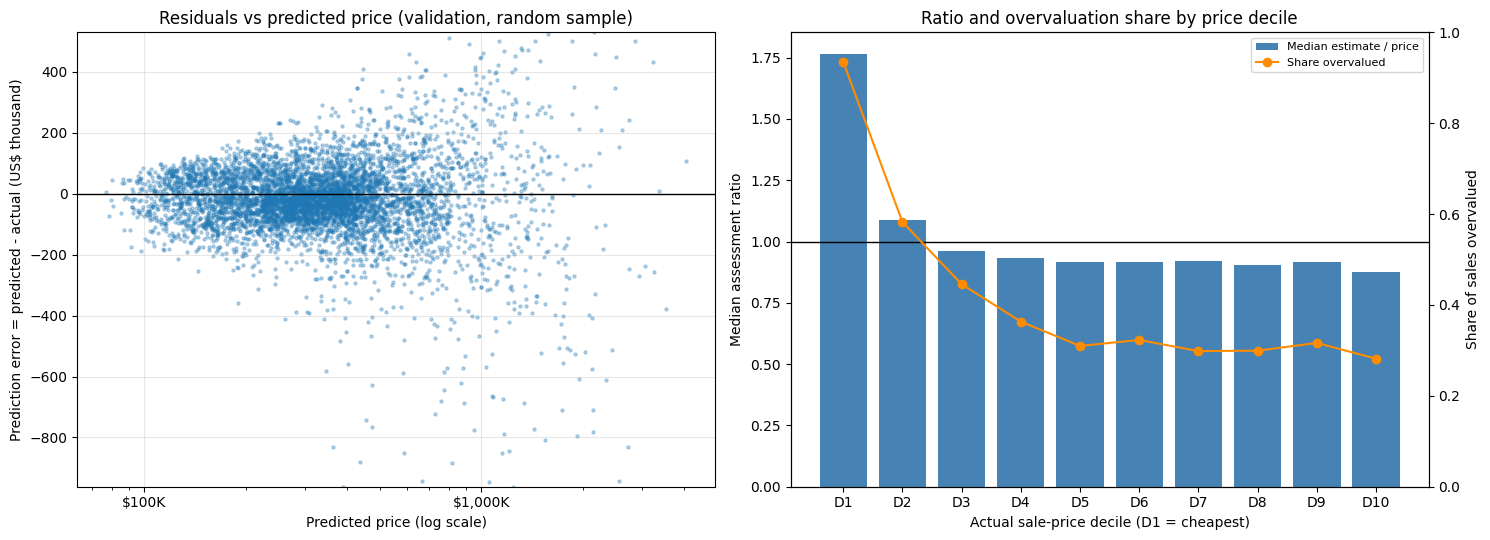

In [16]:
plot_sample = diagnostics.sample(n=min(6000, len(diagnostics)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].scatter(plot_sample["predicted"], plot_sample["error"] / 1e3, s=5, alpha=0.3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}K"))
axes[0].set_xlabel("Predicted price (log scale)")
axes[0].set_ylabel("Prediction error = predicted - actual (US$ thousand)")
axes[0].set_title("Residuals vs predicted price (validation, random sample)")
axes[0].set_ylim(np.percentile(plot_sample["error"] / 1e3, [0.5, 99.5]))
axes[0].grid(alpha=0.3)

decile_positions = np.arange(len(by_decile))
axes[1].bar(decile_positions, by_decile["median_ratio"], color="steelblue", label="Median estimate / price")
axes[1].axhline(1, color="black", linewidth=1)
axes[1].set_xticks(decile_positions)
axes[1].set_xticklabels(by_decile.index)
axes[1].set_xlabel("Actual sale-price decile (D1 = cheapest)")
axes[1].set_ylabel("Median assessment ratio")
twin = axes[1].twinx()
twin.plot(decile_positions, by_decile["share_overvalued"], color="darkorange", marker="o", label="Share overvalued")
twin.set_ylabel("Share of sales overvalued")
twin.set_ylim(0, 1)
axes[1].set_title("Ratio and overvaluation share by price decile")
lines = axes[1].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
labels = axes[1].get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
axes[1].legend(lines, labels, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "T5_rf_validation_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

# Part B — Boosting (M4)

## 8. Boosting family comparison

All Boosting candidates use the same 209 shared predictors (Model A) and the same training and validation rows as Part A. The training-validation split, metric definitions and selection rules are those of the M4 notebook: positive prediction minus actual price is overvaluation, all three WAE values divide by the number of transactions, and predictions are evaluated in dollars after the inverse transformation for log1p targets. The test set is not read in this part.

In [17]:
# Boosting uses exactly the same predictors and rows as the tree models (Model A).
assert not ADD_TIME_TREND and not DROP_COLS, "Part B uses the 209 shared predictors without a time variable."
X_train_A, X_valid_A = X_train, X_val
y_valid = y_val
FEATURES = X_train.columns.tolist()
assert len(FEATURES) == 209 and not {"transaction_id", "property_id"} & set(FEATURES)
validation_ids = val_ids["transaction_id"].astype(str).to_numpy()
validation_dates = val_ids["sale_date"]
PRIMARY_METRIC = MAIN_METRIC
print("Train", X_train_A.shape, "Validation", X_valid_A.shape)

Train (54853, 209) Validation (18132, 209)


### 8a. LightGBM: WAE-driven Optuna search

The search uses 24 trials (TPE sampler, seed 6810; the first two trials are a fixed raw-target and a fixed log1p-target baseline). The target scale is part of the search. Each trial uses early stopping on validation dollar WAE 2:1 (100 rounds, at most 1,400 trees), and the stopping round becomes the frozen tree count of that candidate.

In [18]:
def lgb_model(params, rounds=MAX_BOOST_ROUNDS):
    return lgb.LGBMRegressor(objective='regression', metric='None', n_estimators=rounds,
        random_state=SEED, n_jobs=N_THREADS, verbosity=-1, deterministic=True,
        force_col_wise=True, **params)

def search_lightgbm(X_train, X_valid, variant):
    records, predictions, histories = [], {}, {}
    def objective(trial):
        target = trial.suggest_categorical('target', ['raw', 'log1p'])
        depth = trial.suggest_categorical('max_depth', [4, 6, 8, -1])
        leaves = trial.suggest_int('num_leaves', 8, 48)
        if depth > 0:
            leaves = min(leaves, 2 ** depth)
        params = dict(max_depth=depth, num_leaves=leaves,
            learning_rate=trial.suggest_float('learning_rate', .025, .15, log=True),
            min_child_samples=trial.suggest_int('min_child_samples', 30, 180),
            subsample=trial.suggest_float('subsample', .7, 1.), subsample_freq=1,
            colsample_bytree=trial.suggest_float('colsample_bytree', .65, 1.),
            reg_alpha=trial.suggest_float('reg_alpha', 1e-5, 10., log=True),
            reg_lambda=trial.suggest_float('reg_lambda', .01, 100., log=True))
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        valid_target = np.log1p(y_valid) if target == 'log1p' else y_valid
        model = lgb_model(params)
        history = {}
        def dollar_wae_2_1(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            error = prediction - actual
            return 'dollar_WAE_2_1', float(np.mean(np.abs(error) * np.where(error > 0, 2., 1.))), False
        start = time.time()
        model.fit(X_train, train_target,
            eval_set=[(X_valid, valid_target)], eval_names=['validation'],
            eval_metric=dollar_wae_2_1,
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False),
                       lgb.record_evaluation(history)])
        rounds = int(model.best_iteration_ or MAX_BOOST_ROUNDS)
        prediction = dollars(model.predict(X_valid, num_iteration=rounds), target)
        candidate_id = ('C' if variant == 'A_no_time' else 'T') + f'{trial.number + 1:03d}'
        row = dict(candidate_id=candidate_id, model_family='LightGBM', variant=variant,
            feature_set=variant, target=target, configuration=f'{candidate_id} ({target}, {rounds} trees)',
            params=json.dumps(params, sort_keys=True), n_estimators=rounds,
            n_predictors=X_train.shape[1], elapsed_seconds=time.time() - start,
            **boosting_metrics(y_valid, prediction))
        records.append(row)
        predictions[candidate_id] = prediction
        histories[candidate_id] = history
        trial.set_user_attr('candidate_id', candidate_id)
        trial.set_user_attr('best_iteration', rounds)
        print(variant, candidate_id, 'WAE 2:1', f'{row[PRIMARY_METRIC]:,.2f}', 'trees', rounds, flush=True)
        return row[PRIMARY_METRIC]
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8))
    base = dict(max_depth=6, num_leaves=31, learning_rate=.05, min_child_samples=60,
                subsample=.9, colsample_bytree=.9, reg_alpha=.01, reg_lambda=1.)
    study.enqueue_trial(dict(target='raw', **base))
    study.enqueue_trial(dict(target='log1p', **base))
    study.optimize(objective, n_trials=N_LGB_TRIALS, n_jobs=1, show_progress_bar=False)
    return pd.DataFrame(records), predictions, histories, study

optuna.logging.set_verbosity(optuna.logging.WARNING)
A_trials, A_predictions, A_histories, A_study = search_lightgbm(X_train_A, X_valid_A, 'A_no_time')
A_trials.to_csv(BOOST_OUT / 'lightgbm_A_validation_trials.csv', index=False)
A_study.trials_dataframe().to_csv(BOOST_OUT / 'lightgbm_A_optuna_trials.csv', index=False)
A_winner = A_trials.sort_values([PRIMARY_METRIC, 'candidate_id']).iloc[0]
print('A LightGBM WAE 2:1 winner:', A_winner['configuration'])

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C001 WAE 2:1 132,800.10 trees 852


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C002 WAE 2:1 127,653.43 trees 742


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C003 WAE 2:1 134,577.36 trees 1383


... (38 outputs left out)

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C023 WAE 2:1 127,139.44 trees 851


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


A_no_time C024 WAE 2:1 127,226.38 trees 1091
A LightGBM WAE 2:1 winner: C020 (log1p, 912 trees)


### 8b. Histogram Gradient Boosting

Histogram Boosting keeps its six pre-specified configurations (three settings × raw and log1p targets).

In [19]:
hist_records, hist_predictions = [], {}
hist_grid = [(200,.05,15), (400,.05,31), (400,.1,15)]
for target in ['raw', 'log1p']:
    for rounds, rate, leaves in hist_grid:
        params = dict(max_iter=rounds, learning_rate=rate, max_leaf_nodes=leaves,
                      min_samples_leaf=50, l2_regularization=10.)
        model = HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        start = time.time()
        model.fit(X_train_A, train_target)
        prediction = dollars(model.predict(X_valid_A), target)
        candidate_id = f'H{len(hist_records) + 1:03d}'
        row = dict(candidate_id=candidate_id, model_family='HistGradientBoosting', variant='A_no_time',
            feature_set='A_no_time', target=target,
            configuration=f'{candidate_id} ({target}, {rounds} trees)',
            params=json.dumps(params, sort_keys=True), n_estimators=rounds,
            n_predictors=len(FEATURES), elapsed_seconds=time.time() - start,
            **boosting_metrics(y_valid, prediction))
        hist_records.append(row)
        hist_predictions[candidate_id] = prediction
        print('HistBoost', candidate_id, 'WAE 2:1', f'{row[PRIMARY_METRIC]:,.2f}', flush=True)
Hist_trials = pd.DataFrame(hist_records)
Hist_trials.to_csv(BOOST_OUT / 'histboost_validation_candidates.csv', index=False)
all_candidates = pd.concat([A_trials, Hist_trials], ignore_index=True)
all_candidates.to_csv(BOOST_OUT / 'M4_boosting_candidates.csv', index=False)

HistBoost H001 WAE 2:1 141,114.94
HistBoost H002 WAE 2:1 135,248.25
HistBoost H003 WAE 2:1 136,164.60
HistBoost H004 WAE 2:1 131,733.01
HistBoost H005 WAE 2:1 129,256.11
HistBoost H006 WAE 2:1 129,551.53


### 8c. XGBoost and CatBoost

Following the course examples, use `XGBRegressor` and `CatBoostRegressor` on the shared Train and Validation splits. For each family, fit three fixed settings with raw and log1p targets (six candidates). Models train on Train only. We evaluate predictions in dollars and select directly by validation WAE 2:1, 1:1, or 1:2; fixed tree counts and no early stopping keep the candidate search rule independent of the libraries' default RMSE evaluation. This is a six-candidate comparison per added family, not a 24-trial Optuna search. Test is not read.

In [20]:
# Course-inspired XGBRegressor and CatBoostRegressor; all candidates use the shared A features.
# Keep candidate grids small and explicit, matching HistBoost's six-candidate budget.
xgb_grid = [(400, .05, 4), (600, .05, 6), (800, .03, 6)]
cat_grid = [(400, .05, 6), (600, .05, 6), (800, .03, 8)]
xgb_records, cat_records = [], []
xgb_predictions, cat_predictions = {}, {}
for family, grid, records, predictions, prefix in [
    ('XGBoost', xgb_grid, xgb_records, xgb_predictions, 'X'),
    ('CatBoost', cat_grid, cat_records, cat_predictions, 'K'),
]:
    for target in ['raw', 'log1p']:
        train_target = np.log1p(y_train) if target == 'log1p' else y_train
        for rounds, rate, depth in grid:
            if family == 'XGBoost':
                params = dict(n_estimators=rounds, learning_rate=rate, max_depth=depth,
                              subsample=.9, colsample_bytree=.9, reg_alpha=.01,
                              reg_lambda=1., min_child_weight=5, tree_method='hist')
                model = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED,
                                         n_jobs=N_THREADS, verbosity=0, **params)
            else:
                params = dict(iterations=rounds, learning_rate=rate, depth=depth,
                              l2_leaf_reg=3., bootstrap_type='Bernoulli', subsample=.9,
                              rsm=.9)
                model = CatBoostRegressor(loss_function='RMSE', random_seed=SEED,
                                          thread_count=N_THREADS, verbose=False,
                                          allow_writing_files=False, **params)
            start = time.time()
            model.fit(X_train_A, train_target)
            prediction = dollars(model.predict(X_valid_A), target)
            candidate_id = f'{prefix}{len(records) + 1:03d}'
            row = dict(candidate_id=candidate_id, model_family=family, variant='A_no_time',
                       feature_set='A_no_time', target=target,
                       configuration=f'{candidate_id} ({target}, {rounds} trees)',
                       params=json.dumps(params, sort_keys=True), n_estimators=rounds,
                       n_predictors=len(FEATURES), elapsed_seconds=time.time() - start,
                       **boosting_metrics(y_valid, prediction))
            records.append(row)
            predictions[candidate_id] = prediction
            print(family, candidate_id, 'WAE 2:1', f"{row[PRIMARY_METRIC]:,.2f}", flush=True)
XGB_trials = pd.DataFrame(xgb_records)
Cat_trials = pd.DataFrame(cat_records)
XGB_trials.to_csv(BOOST_OUT / 'xgboost_validation_candidates.csv', index=False)
Cat_trials.to_csv(BOOST_OUT / 'catboost_validation_candidates.csv', index=False)
all_candidates = pd.concat([A_trials, Hist_trials, XGB_trials, Cat_trials], ignore_index=True)
assert all_candidates['candidate_id'].is_unique
all_candidates.to_csv(BOOST_OUT / 'M4_boosting_candidates.csv', index=False)
all_predictions = {**A_predictions, **hist_predictions, **xgb_predictions, **cat_predictions}

XGBoost X001 WAE 2:1 137,743.04
XGBoost X002 WAE 2:1 134,049.54
XGBoost X003 WAE 2:1 133,627.69
XGBoost X004 WAE 2:1 129,069.95
XGBoost X005 WAE 2:1 127,334.69
XGBoost X006 WAE 2:1 127,037.32
CatBoost K001 WAE 2:1 137,804.15
CatBoost K002 WAE 2:1 135,909.62
CatBoost K003 WAE 2:1 134,673.86
CatBoost K004 WAE 2:1 128,851.57
CatBoost K005 WAE 2:1 127,513.39
CatBoost K006 WAE 2:1 127,094.44


## 9. Boosting: scenario-specific selection and fixed prediction comparison

All four families select their own best configuration separately for the three validation WAE scenarios. The main scenario then selects one Boosting model for the fixed prediction comparison with the training mean baseline. The MSE champion table is supplementary.

In [21]:
scenario_rows = []
for family, group in all_candidates.groupby('model_family', sort=True):
    for metric, (scenario, _, _) in SCENARIOS.items():
        winner = group.sort_values([metric, 'candidate_id']).iloc[0]
        scenario_rows.append(dict(model_family=family, scenario=scenario,
            winning_configuration=winner['configuration'], feature_set='A_no_time',
            selected_WAE=winner[metric], MSE=winner['MSE'], R2=winner['R2'], MAE=winner['MAE']))
scenario_columns = ['model_family','scenario','winning_configuration','feature_set','selected_WAE','MSE','R2','MAE']
boost_scenario_winners = pd.DataFrame(scenario_rows)[scenario_columns]
boost_scenario_winners.to_csv(BOOST_OUT / 'scenario_validation_winners.csv', index=False)
boost_mse_champions = all_candidates.sort_values(['MSE','candidate_id']).drop_duplicates('model_family')
boost_mse_champions.to_csv(BOOST_OUT / 'MSE_champions_supplement.csv', index=False)
primary_winner = all_candidates.sort_values([PRIMARY_METRIC,'candidate_id']).iloc[0]
primary_id = primary_winner['candidate_id']
primary_prediction = all_predictions[primary_id]
mean_prediction = np.full(len(y_valid), y_train.mean())
fixed_4c = []
for metric, (scenario, _, _) in SCENARIOS.items():
    model_score = boosting_metrics(y_valid, primary_prediction)[metric]
    baseline_score = boosting_metrics(y_valid, mean_prediction)[metric]
    fixed_4c.append(dict(scenario=scenario, model_family=primary_winner['model_family'],
        winning_configuration=primary_winner['configuration'], selected_WAE=model_score,
        baseline_WAE=baseline_score, reduction_pct=100 * (1 - model_score / baseline_score)))
pd.DataFrame(fixed_4c).to_csv(BOOST_OUT / '4c_fixed_prediction_comparison.csv', index=False)
selected_ids = set()
for _, family_candidates in all_candidates.groupby('model_family'):
    for metric in SCENARIOS:
        selected_ids.add(family_candidates.sort_values([metric, 'candidate_id']).iloc[0]['candidate_id'])
selected_ids = sorted(selected_ids)
boost_prediction_export = pd.DataFrame({'transaction_id':validation_ids, 'actual_sale_price':y_valid})
for candidate_id in selected_ids:
    boost_prediction_export[candidate_id] = all_predictions[candidate_id]
boost_prediction_export.to_csv(BOOST_OUT / 'M4_selected_validation_predictions.csv', index=False)
print(boost_scenario_winners.to_string(index=False))
print('4c primary model:', primary_winner['model_family'], primary_winner['configuration'])

        model_family                                    scenario   winning_configuration feature_set  selected_WAE          MSE       R2           MAE
            CatBoost         Main - Overvaluation Priority (2:1) K006 (log1p, 800 trees)   A_no_time 127094.436526 4.757209e+10 0.750579 101783.642581
            CatBoost          Alternative - Equal Priority (1:1)   K003 (raw, 800 trees)   A_no_time  99239.360198 4.313658e+10 0.773834  99239.360198
            CatBoost Alternative - Undervaluation Priority (1:2)   K003 (raw, 800 trees)   A_no_time 163044.224879 4.313658e+10 0.773834  99239.360198
HistGradientBoosting         Main - Overvaluation Priority (2:1) H005 (log1p, 400 trees)   A_no_time 129256.113801 4.788039e+10 0.748962 102471.843693
HistGradientBoosting          Alternative - Equal Priority (1:1)   H002 (raw, 400 trees)   A_no_time  99840.004135 4.494416e+10 0.764357  99840.004135
HistGradientBoosting Alternative - Undervaluation Priority (1:2)   H002 (raw, 400 trees)   A_n

## 10. Boosting: visualising the learning process

Following the course notebook's training-versus-validation curve, refit each family's already selected main-scenario candidate and track dollar-scale WAE 2:1 as trees are added. These diagnostic refits use fixed selected hyperparameters and tree counts; they do not update the candidate table or select a new model. The XGBoost and LightGBM evaluation callbacks collect every round. CatBoost and HistGradientBoosting use staged predictions at ten-tree intervals. The separate gain plot describes the selected LightGBM A model used in the time-variable comparison. Feature importance is descriptive, not causal.

Learning curve CatBoost K006 last validation WAE 2:1 127,094.44
Learning curve HistGradientBoosting H005 last validation WAE 2:1 129,256.11


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Learning curve LightGBM C020 last validation WAE 2:1 127,137.84
Learning curve XGBoost X006 last validation WAE 2:1 127,037.32


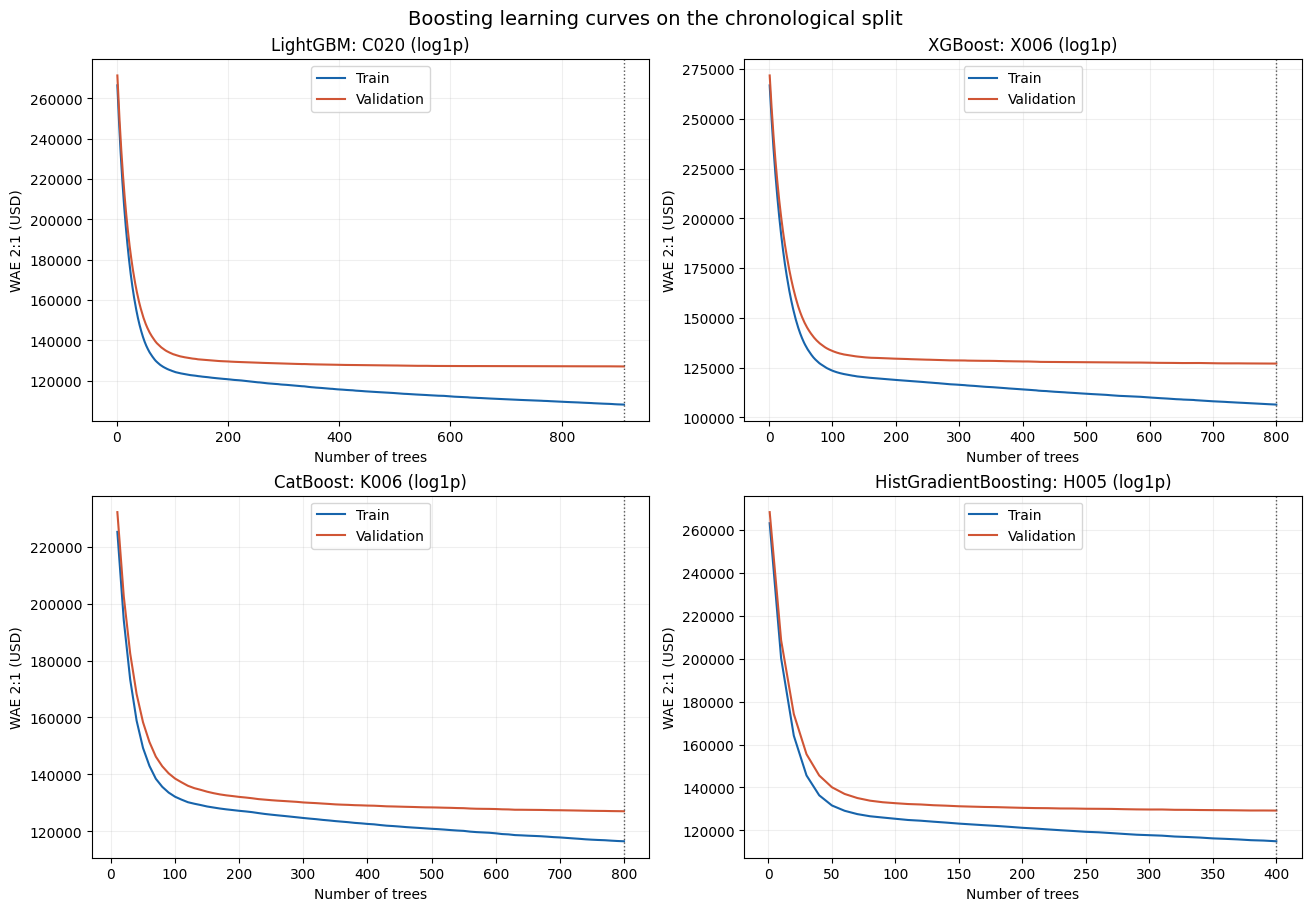

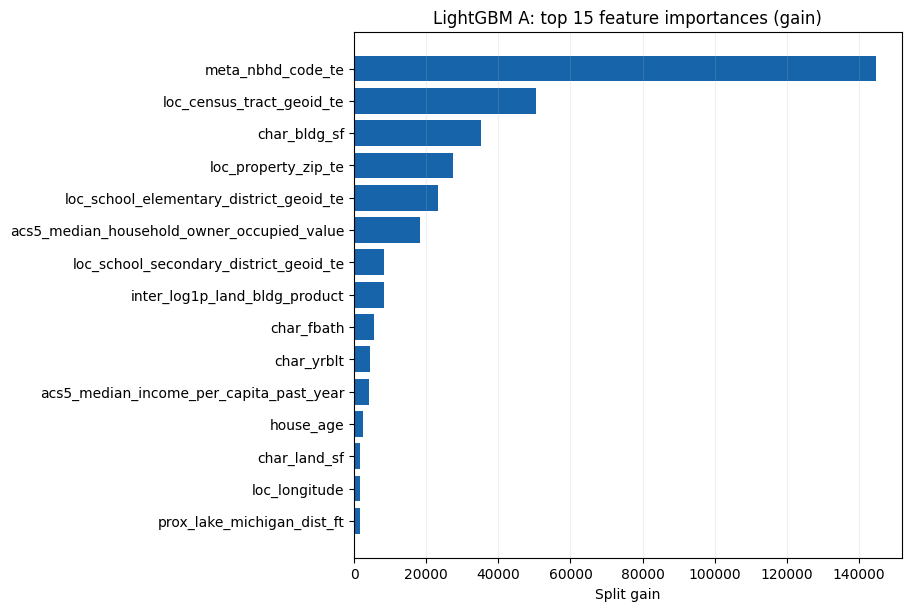

In [22]:
# Diagnostics only: refit selected candidates to collect comparable dollar-WAE learning curves.
def dollar_wae_2_1(actual, prediction):
    error = np.asarray(prediction, dtype=float) - np.asarray(actual, dtype=float)
    return float(np.mean(np.abs(error) * np.where(error > 0, 2., 1.)))

main_scenario = SCENARIOS[MAIN_METRIC][0]
boost_main_winners = boost_scenario_winners.loc[boost_scenario_winners['scenario'].eq(main_scenario)]
curve_rows, visual_models = [], {}
for _, selected in boost_main_winners.iterrows():
    family = selected['model_family']
    candidate_id = selected['winning_configuration'].split(' ', 1)[0]
    candidate = all_candidates.loc[all_candidates['candidate_id'].eq(candidate_id)].iloc[0]
    target = candidate['target']
    rounds = int(candidate['n_estimators'])
    params = json.loads(candidate['params'])
    train_target = np.log1p(y_train) if target == 'log1p' else y_train
    valid_target = np.log1p(y_valid) if target == 'log1p' else y_valid
    if family == 'LightGBM':
        model = lgb_model(params, rounds=rounds)
        history = {}
        def lgb_dollar_wae(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            return 'dollar_WAE_2_1', dollar_wae_2_1(actual, prediction), False
        model.fit(X_train_A, train_target,
                  eval_set=[(X_train_A, train_target), (X_valid_A, valid_target)],
                  eval_names=['training', 'validation'], eval_metric=lgb_dollar_wae,
                  callbacks=[lgb.record_evaluation(history)])
        training_curve = history['training']['dollar_WAE_2_1']
        validation_curve = history['validation']['dollar_WAE_2_1']
        steps = list(range(1, len(validation_curve) + 1))
    elif family == 'XGBoost':
        def xgb_dollar_wae(eval_target, eval_prediction):
            actual = np.expm1(eval_target) if target == 'log1p' else eval_target
            prediction = dollars(eval_prediction, target)
            return dollar_wae_2_1(actual, prediction)
        xgb_dollar_wae.__name__ = 'dollar_WAE_2_1'
        model = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED,
                                 n_jobs=N_THREADS, verbosity=0,
                                 eval_metric=xgb_dollar_wae, **params)
        model.fit(X_train_A, train_target,
                  eval_set=[(X_train_A, train_target), (X_valid_A, valid_target)],
                  verbose=False)
        history = model.evals_result()
        training_curve = history['validation_0']['dollar_WAE_2_1']
        validation_curve = history['validation_1']['dollar_WAE_2_1']
        steps = list(range(1, len(validation_curve) + 1))
    elif family == 'CatBoost':
        model = CatBoostRegressor(loss_function='RMSE', random_seed=SEED,
                                  thread_count=N_THREADS, verbose=False,
                                  allow_writing_files=False, **params)
        model.fit(X_train_A, train_target)
        steps, training_curve, validation_curve = [], [], []
        train_stages = model.staged_predict(X_train_A, ntree_end=rounds, eval_period=10)
        valid_stages = model.staged_predict(X_valid_A, ntree_end=rounds, eval_period=10)
        for step, (train_pred, valid_pred) in enumerate(zip(train_stages, valid_stages), start=1):
            steps.append(min(step * 10, rounds))
            training_curve.append(dollar_wae_2_1(y_train, dollars(train_pred, target)))
            validation_curve.append(dollar_wae_2_1(y_valid, dollars(valid_pred, target)))
    elif family == 'HistGradientBoosting':
        model = HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
        model.fit(X_train_A, train_target)
        steps, training_curve, validation_curve = [], [], []
        train_stages = model.staged_predict(X_train_A)
        valid_stages = model.staged_predict(X_valid_A)
        for step, (train_pred, valid_pred) in enumerate(zip(train_stages, valid_stages), start=1):
            if step == 1 or step % 10 == 0 or step == rounds:
                steps.append(step)
                training_curve.append(dollar_wae_2_1(y_train, dollars(train_pred, target)))
                validation_curve.append(dollar_wae_2_1(y_valid, dollars(valid_pred, target)))
    else:
        raise ValueError(f'Unexpected boosting family: {family}')
    assert steps[-1] == rounds and len(steps) == len(training_curve) == len(validation_curve)
    for step, train_score, valid_score in zip(steps, training_curve, validation_curve):
        curve_rows.append(dict(model_family=family, candidate_id=candidate_id,
                               target=target, n_trees=step,
                               train_WAE_2_1=train_score, validation_WAE_2_1=valid_score))
    visual_models[family] = model
    print('Learning curve', family, candidate_id, 'last validation WAE 2:1',
          f'{validation_curve[-1]:,.2f}', flush=True)
learning_curves = pd.DataFrame(curve_rows)
learning_curves.to_csv(BOOST_OUT / 'learning_curves_WAE_2_1.csv', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, family in zip(axes.flat, ['LightGBM','XGBoost','CatBoost','HistGradientBoosting']):
    group = learning_curves.loc[learning_curves['model_family'].eq(family)]
    ax.plot(group['n_trees'], group['train_WAE_2_1'], label='Train', color='#1764ab')
    ax.plot(group['n_trees'], group['validation_WAE_2_1'], label='Validation', color='#d05535')
    ax.axvline(int(group['n_trees'].iloc[-1]), color='#555555', linestyle=':', linewidth=1)
    ax.set_title(f"{family}: {group['candidate_id'].iloc[0]} ({group['target'].iloc[0]})")
    ax.set_xlabel('Number of trees')
    ax.set_ylabel('WAE 2:1 (USD)')
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('Boosting learning curves on the chronological split', fontsize=14)
fig.savefig(BOOST_OUT / 'learning_curves_WAE_2_1.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# Course-style feature importance for the selected LightGBM A model.
lgb_gain = visual_models['LightGBM'].booster_.feature_importance(importance_type='gain')
importance = pd.DataFrame({'feature': FEATURES, 'gain': lgb_gain}).sort_values('gain', ascending=False)
importance.to_csv(BOOST_OUT / 'lightgbm_feature_importance_gain.csv', index=False)
top = importance.head(15).sort_values('gain')
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.barh(top['feature'], top['gain'], color='#1764ab')
ax.set_xlabel('Split gain')
ax.set_title('LightGBM A: top 15 feature importances (gain)')
ax.grid(axis='x', alpha=.2)
fig.savefig(BOOST_OUT / 'lightgbm_feature_importance_gain.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 11. Boosting: time-variable comparison (Model A vs Model B)

### 11a. Fixed hyperparameters

A uses the 209 shared predictors. B appends months_since_2023_01 from membership sale_date. B uses the A LightGBM WAE 2:1 winner's exact parameters and number of trees. Both fixed fits disable early stopping; this isolates the month variable.

In [23]:
def month_index(dates):
    return ((dates.dt.year - 2023) * 12 + dates.dt.month - 1).astype(int).to_numpy()
train_month_index = month_index(train_ids['sale_date'])
valid_month_index = month_index(validation_dates)
assert train_month_index.min() == 0 and train_month_index.max() == 17
assert valid_month_index.min() == 18 and valid_month_index.max() == 23
X_train_B = X_train_A.assign(months_since_2023_01=train_month_index)
X_valid_B = X_valid_A.assign(months_since_2023_01=valid_month_index)
assert X_train_A.shape[1] == 209 and X_train_B.shape[1] == 210
fixed_params = json.loads(A_winner['params'])
fixed_target = A_winner['target']
fixed_rounds = int(A_winner['n_estimators'])
fixed_predictions = {}
for variant, train_features, valid_features in [
    ('A_no_time', X_train_A, X_valid_A), ('B_month_index', X_train_B, X_valid_B)]:
    model = lgb_model(fixed_params, rounds=fixed_rounds)
    model.fit(train_features, np.log1p(y_train) if fixed_target == 'log1p' else y_train)
    fixed_predictions[variant] = dollars(model.predict(valid_features, num_iteration=fixed_rounds), fixed_target)
    print('Fixed', variant, 'WAE 2:1', f'{boosting_metrics(y_valid, fixed_predictions[variant])[PRIMARY_METRIC]:,.2f}')

Fixed A_no_time WAE 2:1 127,137.84
Fixed B_month_index WAE 2:1 135,841.84


### 11b. Equal budget retuning

B receives the same 24 Optuna trials, seed, WAE 2:1 objective and early stopping rule as A. A's already completed WAE search supplies its retuned row; no second A search is needed.

In [24]:
B_trials, B_predictions, B_histories, B_study = search_lightgbm(X_train_B, X_valid_B, 'B_month_index')
B_trials.to_csv(BOOST_OUT / 'lightgbm_B_validation_trials.csv', index=False)
B_study.trials_dataframe().to_csv(BOOST_OUT / 'lightgbm_B_optuna_trials.csv', index=False)
B_winner = B_trials.sort_values([PRIMARY_METRIC,'candidate_id']).iloc[0]
print('B LightGBM WAE 2:1 winner:', B_winner['configuration'])

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T001 WAE 2:1 149,792.93 trees 57


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T002 WAE 2:1 136,788.81 trees 79


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T003 WAE 2:1 153,804.69 trees 103


... (38 outputs left out)

C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T023 WAE 2:1 135,539.93 trees 62


C:\Users\20166\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


B_month_index T024 WAE 2:1 135,716.37 trees 71
B LightGBM WAE 2:1 winner: T009 (log1p, 90 trees)


### 11c. Group comparison export and predeclared decision

The fixed comparison is the primary isolation check. Adopt B only if its validation WAE 2:1 improves by more than 1%; otherwise retain A. If MAE improves while WAE worsens, retain A and report that tradeoff. Trees cannot extrapolate beyond the observed training month indices; B can at most distinguish the validation period from earlier training months. A already contains year information through house_age and char_yrblt.

The table is also copied to `data/result/time_trend_comparison/inputs/` for the group summary in 3d.

In [25]:
comparison_rows = []
comparison_predictions = {}
for comparison, variant, prediction, configuration, count in [
    ('fixed_hyperparameters','A_no_time',fixed_predictions['A_no_time'], A_winner['configuration'], 209),
    ('fixed_hyperparameters','B_month_index',fixed_predictions['B_month_index'], A_winner['configuration'], 210),
    ('retuned','A_no_time',A_predictions[A_winner['candidate_id']], A_winner['configuration'], 209),
    ('retuned','B_month_index',B_predictions[B_winner['candidate_id']], B_winner['configuration'], 210),
]:
    comparison_predictions[(comparison, variant)] = prediction
    comparison_rows.append(dict(model_family='LightGBM', variant=variant, comparison=comparison,
        configuration=configuration, n_predictors=count, **boosting_metrics(y_valid, prediction)))
comparison_columns = ['model_family','variant','comparison','configuration','n_predictors',
    'MSE','RMSE','R2','MAE','WAE_2_1','WAE_1_1','WAE_1_2',
    'mean_signed_error','median_ratio','share_overvalued']
time_comparison = pd.DataFrame(comparison_rows)[comparison_columns]
time_comparison.to_csv(TIME_OUT / 'M4_boosting_time_trend.csv', index=False)
time_comparison.to_csv(SHARED_TIME_INPUTS / 'M4_boosting_time_trend.csv', index=False)   # copy for the group summary
fixed_A = time_comparison.query("comparison == 'fixed_hyperparameters' and variant == 'A_no_time'").iloc[0]
fixed_B = time_comparison.query("comparison == 'fixed_hyperparameters' and variant == 'B_month_index'").iloc[0]
improvement_pct = 100 * (fixed_A['WAE_2_1'] - fixed_B['WAE_2_1']) / fixed_A['WAE_2_1']
decision = 'adopt_B' if improvement_pct > 1 else 'retain_A'
tradeoff = bool(fixed_B['MAE'] < fixed_A['MAE'] and fixed_B['WAE_2_1'] > fixed_A['WAE_2_1'])
monthly_rows = []
for (comparison, variant), prediction in comparison_predictions.items():
    for month in range(7, 13):
        mask = validation_dates.dt.month.to_numpy() == month
        monthly_rows.append(dict(model_family='LightGBM', variant=variant, comparison=comparison,
            validation_month=f'2024-{month:02d}', n=int(mask.sum()),
            mean_signed_error=float(np.mean(prediction[mask] - y_valid[mask]))))
pd.DataFrame(monthly_rows).to_csv(BOOST_OUT / 'M4_monthly_signed_error.csv', index=False)
time_predictions = pd.DataFrame({'transaction_id':validation_ids,'actual_sale_price':y_valid})
for (comparison, variant), prediction in comparison_predictions.items():
    time_predictions[f'{comparison}_{variant}'] = prediction
time_predictions.to_csv(BOOST_OUT / 'M4_time_validation_predictions.csv', index=False)
boost_time_decision = dict(selection_metric='2024H2 validation WAE_2_1', A_winner=A_winner['configuration'],
    B_winner=B_winner['configuration'], fixed_improvement_pct=improvement_pct,
    decision=decision, MAE_improves_while_WAE_worsens=tradeoff,
    train_month_range=[0,17], validation_month_range=[18,23], test_read=False)
(BOOST_OUT / 'M4_decision.json').write_text(json.dumps(boost_time_decision,indent=2,ensure_ascii=False),encoding='utf-8')
print(time_comparison.to_string(index=False))
print('Fixed comparison WAE improvement:',f'{improvement_pct:.3f}%','decision:',decision,'MAE/WAE tradeoff:',tradeoff)

model_family       variant            comparison           configuration  n_predictors          MSE          RMSE       R2           MAE       WAE_2_1       WAE_1_1       WAE_1_2  mean_signed_error  median_ratio  share_overvalued
    LightGBM     A_no_time fixed_hyperparameters C020 (log1p, 912 trees)           209 4.719801e+10 217251.026721 0.752540 101201.802073 127137.842014 101201.802073 176467.564203      -49329.722189      0.903462          0.337856
    LightGBM B_month_index fixed_hyperparameters C020 (log1p, 912 trees)           210 4.415106e+10 210121.524929 0.768515  96014.066596 135841.844787  96014.066596 152200.354999      -16358.510212      0.979676          0.462001
    LightGBM     A_no_time               retuned C020 (log1p, 912 trees)           209 4.719801e+10 217251.026721 0.752540 101201.802073 127137.842014 101201.802073 176467.564203      -49329.722189      0.903462          0.337856
    LightGBM B_month_index               retuned  T009 (log1p, 90 trees)        

# Part C — Final model and 2025 test

## 12. Final model selection across families (3f)

**Rule (pre-specified).** The final model is the configuration with the lowest 2024 H2 validation WAE 2:1 among all configurations evaluated in Parts A and B. Ties are broken by candidate ID. The time-variable decision from sections 6c and 11 must keep Model A for the selected family, so the final model uses the 209 shared predictors.

The comparison table lists each family's main-scenario winner on the same 18,132 validation sales, plus the Global Mean baseline and, when its result file exists, the linear-model winner from `assignment_6810.ipynb` (for reference only). The frozen choice is written to `final_model_selection.json` before the test set is opened.

In [26]:
METRIC_COLUMNS = ["WAE_2_1", "WAE_1_1", "WAE_1_2", "MSE", "R2", "MAE"]
TREE_TARGET = "log1p" if TARGET == "log" else "raw"

# Candidate pool: every configuration scored on validation in Parts A and B (Model A features).
tree_pool = pd.DataFrame({
    "model_family": all_runs["model_family"],
    "candidate_id": all_runs["run_id"],
    "configuration": all_runs["run_id"] + " (" + all_runs["configuration"] + ")",
    "target": TREE_TARGET,
    "params": all_runs["params"],
    "n_estimators": all_runs["n_estimators"],
    "source": "Part A (trees)",
})
tree_pool = pd.concat([tree_pool, all_runs[METRIC_COLUMNS]], axis=1)
boost_pool = all_candidates[["model_family", "candidate_id", "configuration", "target", "params", "n_estimators"]
                            + METRIC_COLUMNS].assign(source="Part B (Boosting)")
candidate_pool = pd.concat([tree_pool, boost_pool], ignore_index=True)
assert candidate_pool["candidate_id"].is_unique
candidate_pool.to_csv(FINAL_DIR / "validation_candidate_pool.csv", index=False)

family_winners = (candidate_pool.sort_values([MAIN_METRIC, "candidate_id"])
                  .drop_duplicates("model_family").reset_index(drop=True))

# The family winners must agree with the scenario-winner tables of Parts A and B.
main_name = SCENARIOS[MAIN_METRIC][0]
recorded_main = pd.concat([
    scenario_winners.loc[scenario_winners["scenario"] == main_name, ["model_family", "selected_WAE"]],
    boost_scenario_winners.loc[boost_scenario_winners["scenario"] == main_name, ["model_family", "selected_WAE"]],
])
check = family_winners.merge(recorded_main, on="model_family", how="left", validate="one_to_one")
assert check["selected_WAE"].notna().all() and np.allclose(check[MAIN_METRIC], check["selected_WAE"])

final_candidate = family_winners.iloc[0]
FINAL_FAMILY = final_candidate["model_family"]
print(f"Final model: {FINAL_FAMILY} {final_candidate['configuration']}, "
      f"validation WAE 2:1 = {final_candidate[MAIN_METRIC]:,.2f}")

# Time variable: the selected family must keep Model A.
if FINAL_FAMILY in ("Decision Tree", "Random Forest"):
    time_row = time_trend_table.loc[
        (time_trend_table["model_family"] == FINAL_FAMILY)
        & (time_trend_table["selected_by"] == SELECTION_RULES["WAE_2_1"])
        & (time_trend_table["comparison"] == "fixed_hyperparameters")
        & (time_trend_table["variant"] == "B_month_index")
    ].iloc[0]
    time_evidence = f"{FINAL_FAMILY} fixed-hyperparameter comparison: {time_row['rule_outcome']}"
    adopt_time = time_row["rule_outcome"].startswith("Adopt")
else:
    time_evidence = (f"LightGBM fixed-hyperparameter comparison (section 11): {decision}, "
                     f"WAE 2:1 change {-improvement_pct:+.2f}%")
    if FINAL_FAMILY != "LightGBM":
        time_evidence = (f"Model B was not fitted for {FINAL_FAMILY}; Boosting evidence from the "
                         + time_evidence)
    adopt_time = decision == "adopt_B"
assert not adopt_time, ("The time-variable rule adopts Model B for the selected family; "
                        "the final model would then have to be selected from the Model B search.")
print("Time variable:", time_evidence)

# Cross-family comparison table for 3f (validation, main scenario).
comparison = family_winners[["model_family", "configuration"] + METRIC_COLUMNS].assign(
    role=["selected final model"] + ["family winner"] * (len(family_winners) - 1))
reference_rows = [{"model_family": "Global Mean", "configuration": "training-period mean price",
                   **{column: baseline_metrics[column] for column in METRIC_COLUMNS}, "role": "baseline"}]
linear_path = DATA_DIR / "result" / "linear_models" / "overall_model_selection_winners.csv"
if linear_path.exists():
    linear = pd.read_csv(linear_path)
    linear_main = linear.loc[linear["selection_metric"] == MAIN_METRIC].iloc[0]
    reference_rows.append({
        "model_family": f"{linear_main['selected_model_family']} (linear)",
        "configuration": f"Feature Set {linear_main['selected_feature_set']}, alpha={linear_main['selected_alpha']}",
        **{column: float(linear_main[column]) for column in METRIC_COLUMNS},
        "role": "reference: fitted in assignment_6810.ipynb",
    })
    if float(linear_main[MAIN_METRIC]) < final_candidate[MAIN_METRIC]:
        raise RuntimeError("A linear model has the lowest validation WAE 2:1. The final test must then be run "
                           "with that model in assignment_6810.ipynb, not with the model selected here.")
else:
    print(f"{linear_path.as_posix()} not found: the linear winner is not shown in the comparison table.")
family_comparison = (pd.concat([comparison, pd.DataFrame(reference_rows)], ignore_index=True)
                     .sort_values(MAIN_METRIC).reset_index(drop=True))
family_comparison.to_csv(FINAL_DIR / "validation_family_comparison_main_scenario.csv", index=False)
print(f"\nMain-scenario winner of each family (2024 H2 validation, {len(y_val):,} sales):")
print(family_comparison.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

# Freeze the choice before the test set is opened.
final_selection = {
    "selection_rule": "lowest 2024 H2 validation WAE 2:1 across all evaluated configurations",
    "model_family": FINAL_FAMILY,
    "candidate_id": final_candidate["candidate_id"],
    "configuration": final_candidate["configuration"],
    "target": final_candidate["target"],
    "params": json.loads(final_candidate["params"]),
    "n_estimators": None if pd.isna(final_candidate["n_estimators"]) else int(final_candidate["n_estimators"]),
    "predictors": len(FEATURES),
    "time_variable": time_evidence,
    "fit_window_for_test": FINAL_FIT_WINDOW,
    "validation_metrics": {column: float(final_candidate[column]) for column in METRIC_COLUMNS},
    "runner_up": {"model_family": family_winners.iloc[1]["model_family"],
                  "configuration": family_winners.iloc[1]["configuration"],
                  "WAE_2_1": float(family_winners.iloc[1][MAIN_METRIC])},
    "split_sha256": {name: manifest["splits"][name]["sha256"] for name in ["train", "validation", "test"]},
    "frozen_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "test_read": False,
}
(FINAL_DIR / "final_model_selection.json").write_text(json.dumps(final_selection, indent=2), encoding="utf-8")
print("\nFrozen final model written to", (FINAL_DIR / "final_model_selection.json").as_posix())

Final model: XGBoost X006 (log1p, 800 trees), validation WAE 2:1 = 127,037.32
Time variable: Model B was not fitted for XGBoost; Boosting evidence from the LightGBM fixed-hyperparameter comparison (section 11): retain_A, WAE 2:1 change +6.85%

Main-scenario winner of each family (2024 H2 validation, 18,132 sales):
        model_family                                                  configuration      WAE_2_1      WAE_1_1      WAE_1_2                  MSE      R2          MAE                                       role
             XGBoost                                        X006 (log1p, 800 trees) 127,037.3204 101,086.2606 176,221.4614  44,506,225,862.9174  0.7667 101,086.2606                       selected final model
            CatBoost                                        K006 (log1p, 800 trees) 127,094.4365 101,783.6426 178,256.4912  47,572,090,619.5330  0.7506 101,783.6426                              family winner
            LightGBM                                        

## 13. Final 2025 test (4a, 4b, 4c, 4d)

### 13a. Refit the frozen model and predict 2025

The frozen hyperparameters, target scale and tree count are used without change; there is no early stopping and no further tuning. First, the model is refitted on the training sales alone and must reproduce its recorded validation WAE 2:1, which confirms that the refit code builds the same model that was selected. It is then refitted on `FINAL_FIT_WINDOW` (training plus validation sales, 72,985 sales) and predicts the 36,322 sales of 2025 once. The Global Mean baseline is the mean sale price of the same window.

Prediction file schema: `transaction_id, property_id, sale_date, meta_township_code, actual_sale_price, predicted_sale_price, baseline_prediction, model_family, configuration`.

In [27]:
def make_estimator(candidate):
    family = candidate["model_family"]
    params = json.loads(candidate["params"])
    if family == "Decision Tree":
        return DecisionTreeRegressor(random_state=RANDOM_STATE, **params)
    if family == "Random Forest":
        return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
    if family == "LightGBM":
        return lgb_model(params, rounds=int(candidate["n_estimators"]))
    if family == "HistGradientBoosting":
        return HistGradientBoostingRegressor(random_state=SEED, early_stopping=False, **params)
    if family == "XGBoost":
        return xgb.XGBRegressor(objective="reg:squarederror", random_state=SEED,
                                n_jobs=N_THREADS, verbosity=0, **params)
    if family == "CatBoost":
        return CatBoostRegressor(loss_function="RMSE", random_seed=SEED, thread_count=N_THREADS,
                                 verbose=False, allow_writing_files=False, **params)
    raise ValueError(f"Unknown model family: {family}")


def fit_and_predict(candidate, X_fit, y_fit_dollars, X_new):
    target = candidate["target"]
    model = make_estimator(candidate)
    model.fit(X_fit, np.log1p(y_fit_dollars) if target == "log1p" else y_fit_dollars)
    if candidate["model_family"] == "LightGBM":
        raw_prediction = model.predict(X_new, num_iteration=int(candidate["n_estimators"]))
    else:
        raw_prediction = model.predict(X_new)
    return model, dollars(raw_prediction, target)


# Reproduction check on validation: the refit code must rebuild the selected model.
_, reproduced_validation = fit_and_predict(final_candidate, X_train, y_train, X_val)
reproduced_wae = weighted_absolute_error(y_val, reproduced_validation, 2, 1)
relative_gap = abs(reproduced_wae / final_candidate[MAIN_METRIC] - 1)
print(f"Validation WAE 2:1 recorded {final_candidate[MAIN_METRIC]:,.2f}, refit {reproduced_wae:,.2f} "
      f"(relative difference {relative_gap:.2e})")
assert relative_gap < 1e-3, "The refit does not reproduce the selected model's validation result."

if RUN_FINAL_TEST:
    test_raw, test_ids = load_split("test")
    X_test = build_features(test_raw, test_ids)
    assert X_test.columns.tolist() == X_train.columns.tolist() and not X_test.isna().any().any()
    y_test = test_raw["sale_price"].to_numpy(dtype=float)
    assert test_ids["sale_date"].dt.year.eq(2025).all()
    if FINAL_FIT_WINDOW == "train+validation":
        X_fit = pd.concat([X_train, X_val], ignore_index=True)
        y_fit = np.concatenate([y_train, y_val])
        fit_ids = pd.concat([train_ids, val_ids], ignore_index=True)
    else:
        X_fit, y_fit, fit_ids = X_train, y_train, train_ids
    assert fit_ids["transaction_id"].is_unique and not set(fit_ids["transaction_id"]) & set(test_ids["transaction_id"])

    start = time.perf_counter()
    final_model, test_pred = fit_and_predict(final_candidate, X_fit, y_fit, X_test)
    baseline_test = np.full(len(y_test), y_fit.mean())
    print(f"Refit window: {FINAL_FIT_WINDOW} ({len(y_fit):,} sales, {time.perf_counter() - start:.0f}s); "
          f"2025 test sales: {len(y_test):,}")

    township_codes = pd.read_csv(DATA_DIR / "properties_2022.csv", usecols=["property_id", "meta_township_code"],
                                 dtype={"property_id": str, "meta_township_code": str})
    test_output = test_ids[["transaction_id", "property_id", "sale_date"]].merge(
        township_codes, on="property_id", how="left", validate="many_to_one")
    assert len(test_output) == len(test_ids) and test_output["meta_township_code"].notna().all()
    test_output["actual_sale_price"] = y_test
    test_output["predicted_sale_price"] = test_pred
    test_output["baseline_prediction"] = baseline_test
    test_output["model_family"] = FINAL_FAMILY
    test_output["configuration"] = final_candidate["configuration"]
    test_output.to_csv(FINAL_DIR / "final_model_test_predictions.csv", index=False)
    print("Saved", (FINAL_DIR / "final_model_test_predictions.csv").as_posix())
else:
    print("RUN_FINAL_TEST is False: the 2025 test set was not loaded or scored.")

Validation WAE 2:1 recorded 127,037.32, refit 127,037.32 (relative difference 0.00e+00)
Refit window: train+validation (72,985 sales, 14s); 2025 test sales: 36,322
Saved data/result/final_test/final_model_test_predictions.csv


### 13b. Test-set evaluation against the baseline (4a, 4c)

Overall metrics for the final model and the Global Mean baseline: MSE, RMSE, R², MAE, WAE under all three scenarios, median absolute percentage error, mean signed error (prediction − actual), share overvalued, and the IAAO ratio statistics (median ratio, COD, PRD; ratio = estimate / sale price). The 4c table keeps both sets of predictions fixed and changes only the error weights. The residual figure plots prediction errors against predicted price and shows the median ratio and overvaluation share by price decile.

2025 test sales: 36,322; baseline = mean price of the train+validation window ($426,200.21)
                                    WAE_2_1      WAE_1_1      WAE_1_2                  MSE      R2          MAE         RMSE  median_APE  mean_signed_error  share_overvalued  median_ratio     COD    PRD
XGBoost X006                   134,003.2473 105,304.3302 181,909.7431  63,250,763,560.2397  0.7394 105,304.3302 251,497.0448      0.1796       -47,906.4958            0.3693        0.9247 30.8739 1.1554
Global Mean (train+validation) 360,698.9989 256,774.3484 409,624.0464 245,128,678,073.3223 -0.0099 256,774.3484 495,104.7143      0.4279       -48,925.0475            0.6231        1.1839 76.1704 1.8461

4c: WAE with fixed 2025 predictions
                                   scenario        model  model_WAE  baseline_WAE  reduction_percent
        Main - Overvaluation Priority (2:1) XGBoost X006 134,003.25    360,699.00              62.85
         Alternative - Equal Priority (1:1) XGBoost X006 105

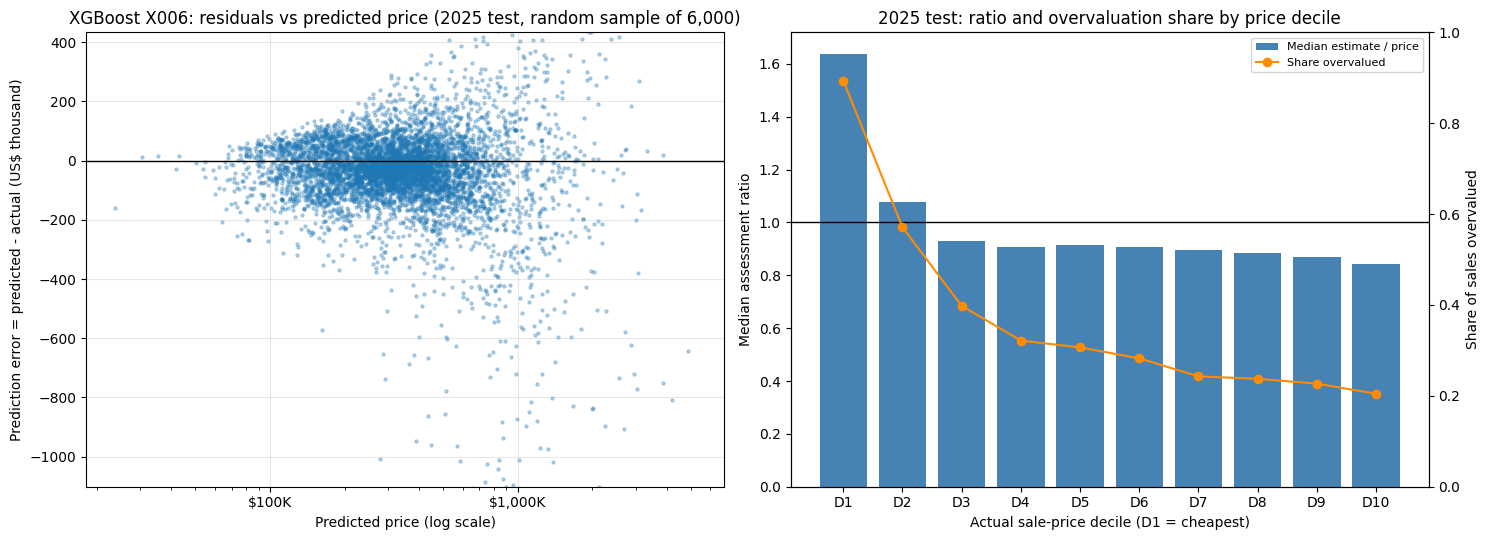

In [28]:
def overall_test_row(actual, prediction):
    error = prediction - actual
    return {
        **evaluate_regression_predictions(actual, prediction),
        "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
        "median_APE": float(np.median(np.abs(error) / actual)),
        "mean_signed_error": float(error.mean()),
        "share_overvalued": float((error > 0).mean()),
        **assessment_ratio_statistics(actual, prediction),
    }


if RUN_FINAL_TEST:
    model_label = f"{FINAL_FAMILY} {final_candidate['candidate_id']}"
    baseline_label = f"Global Mean ({FINAL_FIT_WINDOW})"
    test_overall = pd.DataFrame({model_label: overall_test_row(y_test, test_pred),
                                 baseline_label: overall_test_row(y_test, baseline_test)}).T
    test_overall.to_csv(FINAL_DIR / "final_test_overall_metrics.csv", index_label="model")
    print(f"2025 test sales: {len(y_test):,}; baseline = mean price of the {FINAL_FIT_WINDOW} window "
          f"(${y_fit.mean():,.2f})")
    print(test_overall.to_string(float_format=lambda v: f"{v:,.4f}"))

    fixed_rows = []
    for metric, (scenario_name, over_w, under_w) in SCENARIOS.items():
        model_wae = weighted_absolute_error(y_test, test_pred, over_w, under_w)
        baseline_wae = weighted_absolute_error(y_test, baseline_test, over_w, under_w)
        fixed_rows.append({"scenario": scenario_name, "model": model_label, "model_WAE": model_wae,
                           "baseline_WAE": baseline_wae, "reduction_percent": 100 * (1 - model_wae / baseline_wae)})
    test_fixed = pd.DataFrame(fixed_rows)
    test_fixed.to_csv(FINAL_DIR / "final_test_fixed_scenario_comparison.csv", index=False)
    print("\n4c: WAE with fixed 2025 predictions")
    print(test_fixed.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

    # Summary of the frozen model and its single test evaluation.
    final_metrics = {
        **{key: final_selection[key] for key in ["model_family", "candidate_id", "configuration", "target",
                                                  "params", "n_estimators", "selection_rule", "predictors"]},
        "fit_window": FINAL_FIT_WINDOW, "fit_rows": int(len(y_fit)), "test_rows": int(len(y_test)),
        "test_evaluated_once": True,
        "validation_WAE_2_1": float(final_candidate[MAIN_METRIC]),
        "baseline_fit_mean": float(y_fit.mean()),
        "model": {key: float(value) for key, value in test_overall.loc[model_label].items()},
        "baseline": {key: float(value) for key, value in test_overall.loc[baseline_label].items()},
        "reduction_percent": dict(zip(SCENARIOS, test_fixed["reduction_percent"].astype(float))),
        "split_sha256": final_selection["split_sha256"],
    }
    (FINAL_DIR / "final_model_test_metrics.json").write_text(json.dumps(final_metrics, indent=2), encoding="utf-8")

    # Residual figure (4a).
    test_frame = test_output.rename(columns={"actual_sale_price": "actual", "predicted_sale_price": "predicted"})
    test_frame["error"] = test_frame["predicted"] - test_frame["actual"]
    test_frame["ratio"] = test_frame["predicted"] / test_frame["actual"]
    test_frame["price_decile"] = pd.qcut(test_frame["actual"], 10, labels=[f"D{i}" for i in range(1, 11)])
    decile_view = test_frame.groupby("price_decile", observed=True).agg(
        median_ratio=("ratio", "median"), share_overvalued=("error", lambda e: (e > 0).mean()))
    plot_sample = test_frame.sample(n=min(6000, len(test_frame)), random_state=RANDOM_STATE)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].scatter(plot_sample["predicted"], plot_sample["error"] / 1e3, s=5, alpha=0.3)
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_xscale("log")
    axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v / 1e3:,.0f}K"))
    axes[0].set_xlabel("Predicted price (log scale)")
    axes[0].set_ylabel("Prediction error = predicted - actual (US$ thousand)")
    axes[0].set_title(f"{model_label}: residuals vs predicted price (2025 test, random sample of {len(plot_sample):,})")
    axes[0].set_ylim(np.percentile(plot_sample["error"] / 1e3, [0.5, 99.5]))
    axes[0].grid(alpha=0.3)
    positions = np.arange(len(decile_view))
    axes[1].bar(positions, decile_view["median_ratio"], color="steelblue", label="Median estimate / price")
    axes[1].axhline(1, color="black", linewidth=1)
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(decile_view.index)
    axes[1].set_xlabel("Actual sale-price decile (D1 = cheapest)")
    axes[1].set_ylabel("Median assessment ratio")
    twin = axes[1].twinx()
    twin.plot(positions, decile_view["share_overvalued"], color="darkorange", marker="o", label="Share overvalued")
    twin.set_ylabel("Share of sales overvalued")
    twin.set_ylim(0, 1)
    axes[1].set_title("2025 test: ratio and overvaluation share by price decile")
    handles = axes[1].get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
    labels = axes[1].get_legend_handles_labels()[1] + twin.get_legend_handles_labels()[1]
    axes[1].legend(handles, labels, loc="upper right", fontsize=8)
    plt.tight_layout()
    fig.savefig(FINAL_FIG_DIR / "F1_final_test_residuals.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("RUN_FINAL_TEST is False: section 13b skipped.")

### 13c. Errors by time period, township and price level (4b)

Every table reports the number of sales, the median sale price, error measures (MAE, WAE 2:1, median APE, mean signed error, share overvalued) and the ratio statistics (median ratio, COD, PRD) for the final model's 2025 predictions. Two characteristics from `properties_2022.csv`, median building area and median year built, describe the mix of homes sold in each group. Township names follow the Cook County Assessor's township codes; the seven City of Chicago townships have codes 70–77. "Seen in fit window" marks 2025 sales of properties that also sold in the refit window.


Errors by quarter:
              sales  median_price         MAE     WAE_2_1  median_APE  mean_signed_error  share_overvalued  median_ratio    COD   PRD  median_bldg_sf  median_year_built
sale_quarter                                                                                                                                                            
2025-Q1        7074   340,000.000  99,987.546 130,472.395       0.184        -39,017.850             0.403         0.943 31.013 1.155       1,450.000          1,954.000
2025-Q2       10563   375,000.000 103,875.773 133,229.474       0.171        -45,168.371             0.366         0.928 30.282 1.147       1,464.000          1,954.000
2025-Q3       10094   365,000.000 106,064.844 133,167.042       0.178        -51,860.448             0.351         0.914 30.526 1.151       1,455.500          1,954.000
2025-Q4        8591   357,000.000 110,545.182 138,844.509       0.189        -53,946.527             0.367         0.920 31.750 1.172  

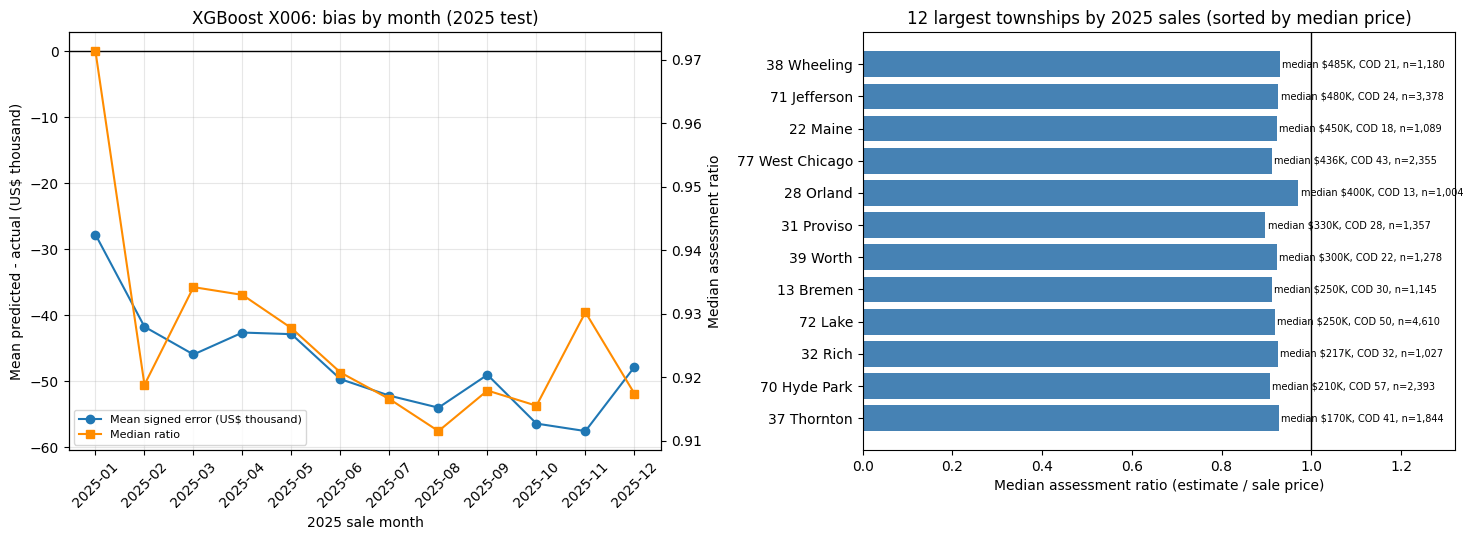

In [29]:
TOWNSHIP_NAMES = {
    "10": "Barrington", "11": "Berwyn", "12": "Bloom", "13": "Bremen", "14": "Calumet", "15": "Cicero",
    "16": "Elk Grove", "17": "Evanston", "18": "Hanover", "19": "Lemont", "20": "Leyden", "21": "Lyons",
    "22": "Maine", "23": "New Trier", "24": "Niles", "25": "Northfield", "26": "Norwood Park", "27": "Oak Park",
    "28": "Orland", "29": "Palatine", "30": "Palos", "31": "Proviso", "32": "Rich", "33": "River Forest",
    "34": "Riverside", "35": "Schaumburg", "36": "Stickney", "37": "Thornton", "38": "Wheeling", "39": "Worth",
    "70": "Hyde Park", "71": "Jefferson", "72": "Lake", "73": "Lake View", "74": "North Chicago",
    "75": "Rogers Park", "76": "South Chicago", "77": "West Chicago",
}


def test_group_summary(frame, by):
    grouped = frame.groupby(by, observed=True)

    def cod(group):
        median = group["ratio"].median()
        return 100 * (group["ratio"] - median).abs().mean() / median

    def prd(group):
        return group["ratio"].mean() / (group["predicted"].sum() / group["actual"].sum())

    ratio_columns = grouped[["ratio", "predicted", "actual"]]
    return pd.DataFrame({
        "sales": grouped.size(),
        "median_price": grouped["actual"].median(),
        "MAE": grouped["abs_error"].mean(),
        "WAE_2_1": grouped["weighted_error_2_1"].mean(),
        "median_APE": grouped["abs_pct_error"].median(),
        "mean_signed_error": grouped["error"].mean(),
        "share_overvalued": grouped["overvalued"].mean(),
        "median_ratio": grouped["ratio"].median(),
        "COD": ratio_columns.apply(cod),
        "PRD": ratio_columns.apply(prd),
        "median_bldg_sf": grouped["bldg_sf"].median(),
        "median_year_built": grouped["year_built"].median(),
    })


if RUN_FINAL_TEST:
    characteristics = pd.read_csv(DATA_DIR / "properties_2022.csv", usecols=["property_id", "char_bldg_sf", "char_yrblt"],
                                  dtype={"property_id": str})
    test_frame = test_frame.merge(characteristics, on="property_id", how="left", validate="many_to_one")
    assert len(test_frame) == len(y_test)
    test_frame = test_frame.rename(columns={"char_bldg_sf": "bldg_sf", "char_yrblt": "year_built"})
    test_frame["abs_error"] = test_frame["error"].abs()
    test_frame["weighted_error_2_1"] = test_frame["abs_error"] * np.where(test_frame["error"] > 0, 2.0, 1.0)
    test_frame["abs_pct_error"] = test_frame["abs_error"] / test_frame["actual"]
    test_frame["overvalued"] = test_frame["error"] > 0
    test_frame["sale_month"] = test_frame["sale_date"].dt.strftime("%Y-%m")
    test_frame["sale_quarter"] = "2025-Q" + test_frame["sale_date"].dt.quarter.astype(str)
    test_frame["township"] = (test_frame["meta_township_code"] + " " +
                              test_frame["meta_township_code"].map(TOWNSHIP_NAMES).fillna("(unnamed)"))
    test_frame["area"] = np.where(test_frame["meta_township_code"].astype(int) >= 70, "City of Chicago", "Suburban Cook")
    test_frame["seen_in_fit_window"] = test_frame["property_id"].isin(set(fit_ids["property_id"]))

    subgroup_tables = {
        "quarter": test_group_summary(test_frame, "sale_quarter"),
        "month": test_group_summary(test_frame, "sale_month"),
        "area": test_group_summary(test_frame, "area"),
        "township": test_group_summary(test_frame, "township").sort_values("sales", ascending=False),
        "price_decile": test_group_summary(test_frame, "price_decile"),
        "seen_status": test_group_summary(test_frame, "seen_in_fit_window"),
    }
    for name, table in subgroup_tables.items():
        table.to_csv(FINAL_DIR / f"final_test_errors_by_{name}.csv")
        shown = table.head(12) if name == "township" else table
        print(f"\nErrors by {name.replace('_', ' ')}{' (12 largest by sales; full table in the CSV)' if name == 'township' else ''}:")
        print(shown.to_string(float_format=lambda v: f"{v:,.3f}"))

    # Figure for 4b: monthly bias and the ratio level of the largest townships.
    by_month = subgroup_tables["month"]
    largest = subgroup_tables["township"].head(12).sort_values("median_price")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    axes[0].plot(by_month.index, by_month["mean_signed_error"] / 1e3, marker="o", label="Mean signed error (US$ thousand)")
    axes[0].axhline(0, color="black", linewidth=1)
    axes[0].set_xlabel("2025 sale month")
    axes[0].set_ylabel("Mean predicted - actual (US$ thousand)")
    axes[0].tick_params(axis="x", rotation=45)
    month_twin = axes[0].twinx()
    month_twin.plot(by_month.index, by_month["median_ratio"], color="darkorange", marker="s", label="Median ratio")
    month_twin.set_ylabel("Median assessment ratio")
    axes[0].set_title(f"{model_label}: bias by month (2025 test)")
    handles = axes[0].get_legend_handles_labels()[0] + month_twin.get_legend_handles_labels()[0]
    labels = axes[0].get_legend_handles_labels()[1] + month_twin.get_legend_handles_labels()[1]
    axes[0].legend(handles, labels, loc="lower left", fontsize=8)
    axes[0].grid(alpha=0.3)
    axes[1].barh(largest.index, largest["median_ratio"], color="steelblue")
    axes[1].axvline(1, color="black", linewidth=1)
    for position, (label, row) in enumerate(largest.iterrows()):
        axes[1].text(row["median_ratio"] + 0.005, position,
                     f"median ${row['median_price'] / 1e3:,.0f}K, COD {row['COD']:.0f}, n={int(row['sales']):,}",
                     va="center", fontsize=7)
    axes[1].set_xlim(0, max(1.2, largest["median_ratio"].max() + 0.35))
    axes[1].set_xlabel("Median assessment ratio (estimate / sale price)")
    axes[1].set_title("12 largest townships by 2025 sales (sorted by median price)")
    plt.tight_layout()
    fig.savefig(FINAL_FIG_DIR / "F2_final_test_month_township.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("RUN_FINAL_TEST is False: section 13c skipped.")

## 14. Output files

Lists every file written by this notebook. Files from earlier versions of the M3 and M4 notebooks that this notebook no longer writes are flagged, so outdated numbers are not cited in the report by mistake.

In [30]:
for folder in [OUT_DIR, BOOST_OUT, FINAL_DIR]:
    print(f"\n{folder.as_posix()}/")
    for path in sorted(folder.rglob("*")):
        if path.is_file():
            print("   ", path.relative_to(folder).as_posix())
print("\nShared time-variable inputs:", sorted(path.name for path in SHARED_TIME_INPUTS.glob("*.csv")))

outdated = [
    DATA_DIR / "result" / "boosting",                                   # old M4 output folder
    FINAL_DIR / "selected_lightgbm_test_metrics.json",                  # old final test (earlier CSVs)
    FINAL_DIR / "selected_lightgbm_test_predictions.csv",
    *sorted(OUT_DIR.glob("final_test_*.csv")),                          # old M3 section 8b outputs
    OUT_DIR / "rf_test_metrics.csv", OUT_DIR / "rf_test_predictions.csv",
    FIG_DIR / "T6_final_test_residuals.png",
]
outdated = [path for path in outdated if path.exists()]
if outdated:
    print("\nOutdated files from earlier notebook versions (not written by this notebook; delete them):")
    for path in outdated:
        print("   ", path.as_posix())


data/result/trees/
    figures/T1_decision_tree_complexity.png
    figures/T2_rf_n_estimators.png
    figures/T3_rf_complexity_grid.png
    figures/T4_rf_feature_importance.png
    figures/T5_rf_validation_residuals.png
    figures/T6_final_test_residuals.png
    figures/T7_time_variable_monthly_bias.png
    final_test_errors_by_month.csv
    final_test_errors_by_price_decile.csv
    final_test_errors_by_quarter.csv
    final_test_errors_by_seen_status.csv
    final_test_errors_by_township.csv
    final_test_fixed_scenario_comparison.csv
    final_test_overall_metrics.csv
    rf_feature_importance.csv
    rf_n_estimators_path.csv
    rf_validation_errors_by_month.csv
    rf_validation_errors_by_price_decile.csv
    rf_validation_errors_by_seen_status.csv
    rf_validation_errors_by_township.csv
    rf_validation_ratio_statistics.csv
    time_trend/model_B_validation_results_all_runs.csv
    time_trend/tree_time_trend_comparison.csv
    time_trend/tree_time_trend_monthly_bias.csv
    t